# Comparativa de trackers para detección de movimiento desde dron — v13

> **Novedades v13 — la cámara de UCMC se calibra sola** (PARTE 3.3b, `calibrar_ucmc`)
> 1. **Pitch por frame, no uno por video.** En varias tomas el gimbal se inclina durante el vuelo (p. ej. `vigia_10` pasa de ~50° a casi cenital). Antes de correr los trackers se hace una pasada rápida con la misma `H` de `compare` y, cada medio segundo, se **descompone la `H` de una ventana de 1 s**: si el suelo es plano, `H` contiene la inclinación del suelo respecto a la cámara (su normal), y de ahí sale el pitch. La descomposición da dos soluciones; se queda la secuencia más **continua en el tiempo** que además respete el **horizonte**: ningún vehículo detectado puede quedar por encima de él.
> 2. **Altura por frame.** La misma descomposición dice cuánto sube o baja el dron entre dos frames (la *forma* de la altura en el tiempo); el tamaño de los vehículos (como en el v12, con el pitch de cada frame) fija la escala en metros.
> 3. **Respaldo:** si el dron casi no se desplaza (la normal no se puede medir; p. ej. tomas `estacionario`) o la `H` falla, se usa la cámara de `UCMC_CAM_POR_VIDEO` (la manual del v12; cenital si el video no está). El origen queda en `ucmc_calib` (`H`, `respaldo` o `H (inestable: revisar)`).
> 4. **UCMC con cámara variable:** el mapeo al suelo cambia frame a frame; la CMC lleva cada track con la cámara anterior a la imagen, la mueve con `H` y lo devuelve al suelo con la cámara nueva.
> 5. **Ablación `ucmc_manual`:** UCMC con la cámara manual del v12, para medir qué aporta la calibración. `ucmc_sin_cmc` usa el pitch mediano calibrado (fijo), como el UCMC "uniforme" original.
> 6. Columnas nuevas (filas de UCMC): `ucmc_pitch_min`, `ucmc_pitch_max`, `ucmc_altura_min`, `ucmc_altura_max`, `ucmc_calib`, `ucmc_calib_cobertura`. `ucmc_pitch_deg` y `ucmc_altura_m` son ahora la **mediana** del video. La calibración se guarda en `comparativa_v13/<video>/calibracion_ucmc.json` y se reutiliza.
> 7. `DETECTOR_POR_VIDEO` incluye las 4 tomas oblicuas (`vigia_8` a `vigia_11` → `"coco"`). Salidas en `comparativa_v13/`.
>
> **Supuestos (revísalos con el Paso A2):** suelo **plano** (en `vigia_11`, ladera de montaña, la `H` describe la ladera y no la carretera), **hfov** conocido (82° por defecto; en tomas muy oblicuas cada 10° de error en el hfov mueve el pitch unos 5°) y **sin alabeo** (roll). Sigue sin haber verdad de terreno: la calibración es plausible, no exacta.
>
> **Novedades v12**
> 1. **UCMCTrack como 4.º tracker** (PARTE 3.3). Tracker de solo movimiento de AAAI 2024 ([corfyi/UCMCTrack](https://github.com/corfyi/UCMCTrack), licencia MIT; el aviso de copyright va en la celda 3.3). Portado a numpy (no necesita `lap` ni `filterpy`) y alimentado con **las mismas detecciones** que los otros tres. Lo que lo distingue:
>    - **Asocia en el plano del suelo, en metros**, no en píxeles: cada detección se proyecta al suelo con los parámetros de la cámara.
>    - **Distancia de Mahalanobis proyectada (MMD)** en lugar de IoU: no exige que las cajas se traslapen, y tiene en cuenta que una caja lejana es más incierta en el suelo que una cercana.
>    - **Kalman de velocidad constante en el suelo** (estado `x, vx, y, vy`).
> 2. **Variantes:** `ucmc` (por defecto) usa la CMC del original (su opción `--cmc`, que en MOT17 activa en **todas** las secuencias con cámara móvil) alimentada con **nuestra `H`**. `ucmc_sin_cmc` es la versión "uniforme" pura (el movimiento de la cámara solo se absorbe como ruido); va como ablación, igual que `botsort_sin_gmc`.
> 3. **Cámara por video** (`UCMC_CAM_POR_VIDEO`, Paso B). UCMC necesita saber cómo mira la cámara al suelo: `pitch_deg` (0 = cenital), `hfov_deg` y `altura_m`. La altura se **estima sola** (`"auto"`) con el tamaño de los vehículos detectados. Los pitch de las tomas oblicuas están **estimados a ojo**: compruébalos con `ver_rejilla_ucmc()` (Paso A2) antes de sacar conclusiones de esos videos.
> 4. Métricas nuevas (solo filas de UCMC): `ucmc_pitch_deg`, `ucmc_altura_m`, `ucmc_dets_fuera` (detecciones que no cortan el suelo).
> 5. Salidas en `comparativa_v12/`. Mosaico de 3 × 2 (4 trackers + panel).
>    *(v13: la cámara ahora se calibra sola; ver arriba.)*
>
> **Parámetros de UCMC fijados ANTES de evaluar** (`[UCMC]` en Config): los de `demo.py` del repo original, que es su ejemplo de **tráfico vehicular** (`a = 100`, `wx = wy = 5`, `vmax = 10 m/s`). Los resultados publicados en MOT17 usan parámetros **ajustados secuencia por secuencia**; aquí no se ajustan con nuestros videos, por la misma razón que no se ajustan los ruidos del Kalman propio.
>
> **Novedades v11**
> 1. **Detector elegido por video** (Paso B). YOLO-OBB (DOTA) está entrenado con imágenes cenitales: en la órbita oblicua de `vigia_8` no ve las motos ni la mayoría de los camiones (6 detecciones en el frame 300, frente a 10 de YOLO COCO). Pero COCO no sirve para las tomas cenitales: en `vigia_1` a `vigia_6` detecta de 0 a 0.9 vehículos por frame, frente a 5-66 del OBB. Por eso no hay un detector único:
>    - `DETECTORES` define los dos: `"obb"` (por defecto) y `"coco"` (`car`, `truck`, `bus`, `motorcycle`).
>    - `DETECTOR_POR_VIDEO` dice qué videos usan otro detector (de inicio, `vigia_8` → `"coco"`).
>    - Dentro de cada video los tres trackers siguen recibiendo **las mismas detecciones**: la comparación entre trackers sigue siendo justa.
>    Medido en `vigia_8` completo (propio_kf): vida media 0.81 s → 1.39 s, objetos simultáneos 4.1 → 12.2.
> 2. **Columna `detector` en las métricas.** `comparar_carpeta()` reprocesa un video si sus resultados se hicieron con otro detector.
> 3. Las salidas van a `comparativa_v11/`.
>
> **Cuidado al comparar entre videos:** con detectores distintos, las cifras absolutas (objetos, vida media) de `vigia_8` no son comparables con las de los demás videos. Lo comparable es la posición relativa de los trackers dentro de cada video.
>
> **Novedades v10**
> 1. **Cajas que juntaban varios objetos: corregido en el pipeline** (PARTES 2.3 y 4.2). Tras el v9 seguían apareciendo, sobre todo en `vigia_1`. Causas medidas:
>    - Un auto detectado por YOLO **absorbía fragmentos sin clase** vecinos (su propia estela o un auto que YOLO no veía) → ahora un track con clase **nunca** se fusiona.
>    - En los frames en que YOLO "parpadea", la **propuesta por diferencia de imagen** (auto + estela, más grande) ocupaba su lugar → ahora se descartan las propuestas que se solapan con detecciones YOLO del último medio segundo (`MemoriaYolo`).
>    - La dilatación de las propuestas unía autos vecinos → `dilate` 5 → 3 (y `min_area` 40 → 25, el equivalente geométrico).
>    Medido en 250 frames: cajas fusionadas en `vigia_3` 2.4 % → 0.4 %; cajas sin clase de más de 1.8 vehículos en `vigia_2` 3.4 % → 0 %; en `vigia_1` 42 % → 33 %.
> 2. **Comparativa principal: PROPIO (Kalman + `H`) frente a ByteTrack y BoT-SORT.** Las variantes del v9 (`propio` sin Kalman, `propio_kf_sin_h`) siguen disponibles en `kinds` para ablaciones.
> 3. **Métricas nuevas de cajas:** `cajas_fusionadas_pct` y `cajas_grandes_sin_clase_pct`, para vigilar este problema en cada corrida.
> 4. `comparar_carpeta()` **reprocesa** un video si su `metricas.csv` no tiene todas las variantes pedidas (en el v9 reutilizaba resultados incompletos).
>
> **Límite conocido (detector, no tracker):** en `vigia_1` YOLO-OBB no detecta los autos que cruzan la intersección (sí los estacionados), con ninguna resolución probada (640-1920) ni con `tiles`. Esos autos solo se siguen con propuestas, cuyas cajas incluyen parte de la estela. Arreglarlo requiere otro detector (un OBB más grande o reentrenado con imágenes VIGIA).
>
> **Novedades v9** (tras analizar los 6 videos de `videos_VIGIA` con el v8):
> 1. **Fusión de cajas corregida** (PARTE 4.2). En el v8, `fuse_moving` unía autos distintos que circulaban en fila por el mismo carril (hasta 12 tracks en una sola caja en `vigia_3`). Ahora dos tracks que YOLO clasificó por separado nunca se fusionan, y los fragmentos sin clase solo se unen si casi se tocan.
> 2. **Métricas comparables** (PARTE 6.0). `ids_emitidos` cuenta lo mismo en los tres trackers (IDs con ≥ 2 detecciones). Se añaden `vida_media_s` y `tracks_por_objeto`, que no dependen de cuántos objetos ve cada tracker.
> 3. **Movimiento de la cámara medido por video** (`mov_camara_px_*`, `tipo_toma`). Sin él no se sabe si un video pone a prueba la compensación: 3 de los 6 videos del v8 eran en vuelo estacionario.
> 4. **Una carpeta por video** (`comparativa_v9/<video>/`) y **lote completo** con detección de videos duplicados (PARTE 6.1). Ya no hay que renombrar salidas a mano.
> 5. **Tracker propio + Kalman** (PARTE 3.1b): variantes `propio_kf` (Kalman + `H`) y `propio_kf_sin_h` (Kalman sin compensar). Separan el efecto de Kalman del efecto de la compensación, que en el v8 estaban mezclados.
>
> **Novedad v8:** nuevo filtro de paralaje *temporal* (`parallax_mode="temporal"`, PARTE 4.1). El del v7 nunca se activaba cuando el dron desciende sobre objetos altos (poste de `input1.mp4`). Todo lo demás es idéntico al v7. Cada tracker tiene además su notebook individual: `tracker_propio.ipynb`, `tracker_bytetrack.ipynb`, `tracker_botsort.ipynb` (mismo motor, copiado tal cual).

**Objetivo.** Ver qué objetos se mueven *de verdad* (no por el movimiento del dron), y comparar cuatro formas de seguirlos.

## Qué es igual y qué cambia entre los trackers

| Paso | ¿Igual para todos? |
|---|---|
| Movimiento de la cámara (homografía) | **Sí** |
| Detecciones (YOLO + cambios de imagen sin clase) | **Sí** |
| **Tracker: cómo se une una detección con la anterior** | **NO ← lo único que cambia** |
| Decisión "móvil / estático", filtro de paralaje, fusión de cajas, dibujo | **Sí** |

Los trackers: **1) PROPIO** (compensa la cámara con nuestra homografía), **2) BYTETRACK** de Ultralytics (no compensa la cámara) y **3) BOTSORT** de Ultralytics (compensa con su GMC) y **4) UCMCTRACK** (v12: asocia en el suelo con MMD; CMC con nuestra `H`). Opcional: **BOTSORT sin GMC**. v9: además **1b) PROPIO + KALMAN** y **1c) PROPIO + KALMAN sin compensar** (PARTE 3).

## Por qué en un tramo tranquilo se ven casi iguales
Como todo es compartido salvo la asociación, **la diferencia solo aparece cuando asociar es difícil**: cámara que se mueve rápido, oclusiones, muchos objetos juntos. En tu primer mosaico solo el 0.1-0.3 % de los píxeles diferían entre paneles: la cámara casi no se movía y había pocos objetos. Por eso el mosaico incluye un panel de métricas en vivo.

## Orden de ejecución
`PARTE 1` → `PARTE 2` → … → `PARTE 5` (solo definen cosas; no tocar) → `PARTE 6` (aquí se ejecuta sobre el video completo y se mira el resultado).

In [1]:
# ======================================================================
# IMPORTACIONES
# Qué hace : Carga las librerías
# ¿Se toca? : No
# ======================================================================
import csv
import hashlib                     # v9: detectar videos duplicados por contenido
import os
from collections import deque, defaultdict
from dataclasses import dataclass
from pathlib import Path            # v9: una carpeta de salida por video

import cv2
import numpy as np
from scipy.optimize import linear_sum_assignment

## PARTE 1 — Configuración (lo único que se ajusta)
Todos los parámetros están agrupados por etiqueta: `[CAMARA]`, `[TRACKER PROPIO]`, `[MOVIMIENTO]`, `[PROPUESTAS]`, `[CLASE]`, `[PARALAJE]`, `[FUSION]`. Los marcados *igual para TODOS los trackers* afectan a la comparativa completa. Las distancias están en píxeles de la resolución de trabajo (`work_width`).

In [2]:
# ======================================================================
# PARTE 1 · Config
# Qué hace : Todos los parámetros del sistema
# ¿Se toca? : SÍ — aquí se ajusta todo
# ======================================================================
@dataclass
class Config:
    work_width: int = 960          # ancho al que se estima el movimiento global y se hace el tracking
    out_width: int = 1920          # ancho del video de salida (0 = resolución original)
    # [CAMARA] movimiento global de la cámara (homografía)
    min_inliers: int = 30          # por debajo, la homografía se considera poco fiable
    ransac_px: float = 1.5         # tolerancia RANSAC: más baja = se ajusta más al plano del suelo
    grid: tuple = (4, 3)           # (cols, filas): reparte los puntos por toda la imagen (evita que domine una zona)
    # [TRACKER PROPIO] cómo se une una detección con un track entre frames
    conf_high: float = 0.35        # detecciones "fuertes" (1ª asociación, crean tracks nuevos)
    conf_low: float = 0.10         # detecciones "débiles" (2ª asociación, estilo ByteTrack)
    match_iou: float = 0.20        # IoU mínimo (con cajas infladas) para asociar
    box_pad: float = 3.0           # px con que se inflan las cajas para el IoU (objetos pequeños)
    max_miss_sec: float = 1.0      # segundos que un track sobrevive sin detección
    min_hits: int = 4              # detecciones para confirmar un track
    # [KALMAN] solo para "propio_kf" y "propio_kf_sin_h" (v9). Son los valores por defecto de ByteTrack/BoT-SORT:
    # NO ajustarlos con los videos de evaluación (sesgaría la comparativa a favor del propio)
    kf_std_pos: float = 1 / 20     # ruido de posición, como fracción de la altura de la caja
    kf_std_vel: float = 1 / 160    # ruido de velocidad, como fracción de la altura de la caja
    # [MOVIMIENTO] cuándo un track cuenta como 'en movimiento' (igual para TODOS los trackers)
    window_sec: float = 1.0        # ventana temporal para medir el desplazamiento neto
    min_move_px: float = 6.0       # desplazamiento mínimo (en la ventana) para considerar movimiento
    rel_move: float = 0.30         # ...y además >= rel_move * tamaño del objeto (sqrt(ancho*alto)); frena cajas grandes inestables
    adaptive: bool = False         # umbral adaptativo con la población de tracks (solo si la mayoría es estática)
    max_adaptive_px: float = 12.0  # tope del umbral adaptativo
    mad_k: float = 4.0             # umbral adaptativo = mediana + k*MAD de la población de tracks
    max_box_area_frac: float = 0.03  # se descartan detecciones con caja mayor a esta fracción del frame
    on_frames: int = 3             # evaluaciones seguidas "moviéndose" para activar el estado
    off_frames: int = 10           # evaluaciones seguidas "quieto" para desactivarlo
    # [PROPUESTAS] cambios de imagen sin clase: objetos que YOLO no conoce (igual para TODOS los trackers)
    use_proposals: bool = True
    proposal_gap_sec: float = 0.15 # separación temporal entre los frames que se restan
    diff_thr: int = 25
    min_area: int = 25             # v10: 40 -> 25 (mismo umbral que antes, corregido por la menor dilatación)
    max_area: int = 6000
    dilate: int = 3                # v10: 5 -> 3 (con 5 se unían los blobs de autos vecinos)
    border: int = 15
    max_aspect: float = 5.0
    max_residual: float = 3.5      # diferencia media tras alinear; si se supera, se omiten propuestas
    proposal_conf: float = 0.5
    proposal_memory_sec: float = 0.5   # v10: segundos que se recuerdan las detecciones YOLO (compensadas con H)
    proposal_overlap: float = 0.2      # v10: se descarta la propuesta si esta fracción de su área cae sobre una detección recordada
    max_coherence: float = 0.80    # estructura de una sola orientación (cables, líneas, bordillos) -> no es un objeto
    min_straightness: float = 0.60 # desplazamiento neto / recorrido en la ventana; un objeto real avanza en línea, el ruido deambula
    # [CLASE] evita que una detección suelta de baja confianza cambie la etiqueta de un track
    cls_min_conf: float = 0.40     # solo las detecciones con esta confianza votan por una clase
    cls_min_hits: int = 3          # votos mínimos para que el track adopte una clase; si no, queda "desconocido"
    # [PARALAJE] lo que sobresale del suelo se desplaza respecto a él cuando el dron se traslada
    parallax_filter: bool = True
    parallax_mode: str = "temporal"    # "temporal" (v8, recomendado) | "ratio" (criterio del v7, para comparar)
    parallax_angle_deg: float = 30.0   # el residuo debe ser paralelo al flujo del suelo en ese punto
    parallax_ratio: float = 0.15       # [solo "ratio"] h/Z máximo; con el dron bajo (poste) NUNCA se cumple
    parallax_k_min: float = -1.5       # [solo "temporal"] k<0: algo fijo en la IMAGEN (cable que resbala, borde)
    parallax_k_max: float = 3.0        # [solo "temporal"] k>0: paralaje; en input1 el poste llega a k≈2.5
    parallax_min_fit: float = 0.6      # [solo "temporal"] R² mínimo del ajuste  residuo(t) ≈ k·flujo_suelo_acumulado(t)
    parallax_min_ground_px: float = 3.0  # [solo "temporal"] flujo NETO del suelo mínimo en la ventana (en hover no se decide)
    parallax_skip: tuple = ("car", "truck", "bus", "motorcycle", "small vehicle", "large vehicle")  # clases que NO se filtran
    show_parallax: bool = True     # dibujar en gris lo descartado por paralaje
    id_badge: bool = True          # dibuja el ID en un recuadro de color (cada ID, un color): los cambios de ID se ven
    debug_residual: bool = False   # guarda un segundo video con el residuo (frame - frame previo compensado) y las cajas
    # [FUSION] fragmentos SIN CLASE que se mueven juntos = una sola caja (v10: los tracks con clase nunca se fusionan)
    merge_motion: bool = True
    merge_gap: float = 0.15        # separación máxima entre cajas, como fracción del lado mayor (v8: 0.6 -> unía autos en fila)
    merge_known: bool = False      # ¿un track con clase puede fusionarse? v8: sí (bug); v9: solo con fragmentos sin clase; v10: nunca
    merge_angle_deg: float = 25.0  # diferencia máxima de dirección
    merge_speed_ratio: float = 0.35  # diferencia relativa máxima de velocidad
    merge_max_aspect: float = 4.0  # si el grupo fusionado sería más alargado que esto (y sin clase), NO se fusiona
    max_unknown_aspect: float = 6.0  # un track SIN clase más alargado que esto es una estructura (cable, borde), no un objeto
    # [UCMC] v12: UCMCTrack. Valores de demo.py del repo original (ejemplo de tráfico vehicular), fijados ANTES de
    # evaluar: NO ajustarlos con los videos de evaluación (sesgaría la comparativa). Umbrales de confianza y
    # ventana de pérdida: los comunes de arriba (conf_high, conf_low, max_miss_sec), igual que ByteTrack/BoT-SORT.
    ucmc_a: float = 100.0          # umbral de asignación (costo MMD = Mahalanobis² + log|S|)
    ucmc_wx: float = 5.0           # ruido de proceso en x (aceleración, (m/s²)²)
    ucmc_wy: float = 5.0           # ruido de proceso en y
    ucmc_vmax: float = 10.0        # velocidad máxima esperada al nacer el track (m/s): incertidumbre inicial
    ucmc_uv_ratio: float = 0.05    # error de la detección en píxeles = 5 % de la altura de la caja (con topes)
    ucmc_punto: str = "auto"       # punto de apoyo en el suelo: "base" (original), "centro" o "auto" (centro si pitch < 30°)
    ucmc_largo_vehiculo_m: float = 4.5    # tamaño real supuesto de un vehículo para estimar la altura ("auto")
    ucmc_altura_defecto_m: float = 100.0  # si no hay vehículos para estimarla
    # [UCMC · calibración] v13: calibrar_ucmc (pitch por frame con la H, altura con los vehículos).
    ucmc_calibrar: bool = True            # False = usar tal cual la cámara de UCMC_CAM_POR_VIDEO (como el v12)
    ucmc_calib_ventana_s: float = 1.0     # separación de los dos frames cuya H se descompone
    ucmc_calib_min_t: float = 0.03        # desplazamiento mínimo del dron en la ventana (relativo a la distancia al suelo)
    ucmc_calib_max_roll: float = 25.0     # soluciones con más alabeo que esto se descartan (el gimbal mantiene el roll ~0)
    ucmc_calib_min_cobertura: float = 30.0  # % de ventanas con estimación; por debajo se usa el pitch de respaldo
    ucmc_calib_max_salto: float = 20.0    # °/s: si el pitch salta más, la estimación se marca como inestable
    ucmc_calib_frames_detector: int = 24  # frames donde se corre el detector (altura y horizonte)

## PARTE 2 — Motor compartido (igual para los tres trackers)
### 2.1 Movimiento de la cámara
**Entra:** dos frames consecutivos. **Sale:** la matriz `H` que explica cómo se movió la cámara (homografía). Con `H` se pueden expresar las posiciones respecto al suelo y no a la pantalla.

In [3]:
# ======================================================================
# 2.1 · GlobalMotion
# Qué hace : Estima el movimiento de la cámara entre frames (LK + RANSAC)
# ¿Se toca? : No
# ======================================================================
def warp_pts(H, pts):
    pts = np.asarray(pts, np.float32).reshape(-1, 2)
    if len(pts) == 0:
        return pts
    return cv2.perspectiveTransform(pts.reshape(-1, 1, 2), H).reshape(-1, 2)


class GlobalMotion:
    """Estima la homografía H (frame previo -> frame actual) con LK + RANSAC."""

    def __init__(self, cfg):
        self.cfg = cfg
        self.prev = None

    def _features(self, gray):
        """Puntos repartidos en una rejilla, para que ninguna zona (techos, pastizal) domine la homografía."""
        h, w = gray.shape
        gx, gy = self.cfg.grid
        pts = []
        for i in range(gy):
            for j in range(gx):
                y0, y1, x0, x1 = i * h // gy, (i + 1) * h // gy, j * w // gx, (j + 1) * w // gx
                p = cv2.goodFeaturesToTrack(gray[y0:y1, x0:x1], 150, 0.01, 8)
                if p is not None:
                    p = p.reshape(-1, 2) + np.array([x0, y0], np.float32)
                    pts.append(p)
        return np.vstack(pts).reshape(-1, 1, 2).astype(np.float32) if pts else None

    def step(self, gray):
        if self.prev is None:
            self.prev = gray
            return np.eye(3), True
        H, ok = np.eye(3), False
        p0 = self._features(self.prev)
        if p0 is not None and len(p0) >= 10:
            p1, st, _ = cv2.calcOpticalFlowPyrLK(self.prev, gray, p0, None, winSize=(21, 21), maxLevel=3)
            good = st.ravel() == 1
            if good.sum() >= 10:
                Hc, inl = cv2.findHomography(p0[good], p1[good], cv2.RANSAC, self.cfg.ransac_px)
                if Hc is not None and inl.sum() >= self.cfg.min_inliers:
                    H, ok = Hc, True
        self.prev = gray
        return H, ok

### 2.2 Detectores
**Entra:** un frame. **Sale:** cajas `[x1,y1,x2,y2,conf,clase]`. `YoloDetector` solo detecta (no hace tracking). Cualquier otro detector (DETR…) se conecta devolviendo ese mismo formato.

In [4]:
# ======================================================================
# 2.2 · YoloDetector
# Qué hace : Detecta objetos con un modelo YOLO (incluye modelos aéreos OBB)
# ¿Se toca? : Solo sus parámetros al crearlo (modelo, imgsz, conf)
# ======================================================================
def resolve_class_ids(names, wanted):
    """Convierte nombres de clase (p. ej. "small vehicle") en los ids del modelo. names = model.names."""
    inv = {str(v).lower(): k for k, v in names.items()}
    ids, missing = [], []
    for w in wanted:
        (ids if str(w).lower() in inv else missing).append(inv.get(str(w).lower(), w))
    if missing:
        raise ValueError(f"Clases que no existen en el modelo: {missing}. Disponibles: {sorted(inv)}")
    return ids


class YoloDetector:
    """Solo DETECTA (predict), no hace tracking. El tracking lo hace nuestro Tracker."""

    def __init__(self, weights="yolo11n.pt", imgsz=1280, conf=0.10, classes=None,
                 device=None, tiles=None, overlap=0.2, class_names=None, nombre=None):
        from ultralytics import YOLO
        self.model = YOLO(weights)
        self.names = self.model.names
        self.nombre = nombre or Path(str(weights)).stem   # v11: se guarda en metricas.csv (columna detector)
        if class_names:                              # filtrar por NOMBRE: no hace falta saber los ids del modelo
            classes = resolve_class_ids(self.names, class_names)
        self.imgsz, self.conf, self.classes, self.device = imgsz, conf, classes, device
        self.tiles, self.overlap = tiles, overlap      # tiles=(filas, columnas) o None

    def _predict(self, img):
        r = self.model.predict(img, imgsz=self.imgsz, conf=self.conf, classes=self.classes,
                               device=self.device, verbose=False)[0]
        b = getattr(r, "obb", None)          # modelos *-obb (DOTA): cajas orientadas; se usa su caja horizontal
        if b is None:
            b = r.boxes
        if b is None or len(b) == 0:
            return np.zeros((0, 6), np.float32)
        return np.concatenate([b.xyxy.cpu().numpy(), b.conf.cpu().numpy()[:, None],
                               b.cls.cpu().numpy()[:, None]], 1).astype(np.float32)

    def __call__(self, frame_bgr, scale):
        if not self.tiles:
            d = self._predict(frame_bgr)
        else:
            import torch, torchvision
            H, W = frame_bgr.shape[:2]
            rows, cols = self.tiles
            th, tw = H / rows, W / cols
            outs = []
            for i in range(rows):
                for j in range(cols):
                    y0, y1 = int(max(0, i * th - self.overlap * th)), int(min(H, (i + 1) * th + self.overlap * th))
                    x0, x1 = int(max(0, j * tw - self.overlap * tw)), int(min(W, (j + 1) * tw + self.overlap * tw))
                    t = self._predict(frame_bgr[y0:y1, x0:x1])
                    t[:, [0, 2]] += x0
                    t[:, [1, 3]] += y0
                    outs.append(t)
            d = np.concatenate(outs, 0) if outs else np.zeros((0, 6), np.float32)
            if len(d):
                keep = torchvision.ops.batched_nms(torch.from_numpy(d[:, :4]), torch.from_numpy(d[:, 4]),
                                                   torch.from_numpy(d[:, 5]).long(), 0.5).numpy()
                d = d[keep]
        d[:, :4] *= scale          # a coordenadas de trabajo
        return d

### 2.3 Propuestas de movimiento (objetos que YOLO no conoce)
Diferencia entre el frame actual y uno anterior ya compensado por `H`. Genera cajas **sin clase** (`desconocido`) para cosas en movimiento que ningún modelo etiqueta (paracaídas, peatones vistos desde arriba).

**`MemoriaYolo` (v10).** Recuerda las detecciones de YOLO del último medio segundo, compensadas con `H`. Una propuesta que cae en buena parte (`proposal_overlap`) sobre alguna de ellas se descarta: ese objeto ya lo conoce YOLO. Así, cuando YOLO pierde un auto durante un frame, la propuesta de ese auto (más grande, porque incluye su estela) no ocupa su lugar. Va en el motor compartido: los tres trackers reciben exactamente las mismas detecciones.

In [5]:
# ======================================================================
# 2.3 · MotionProposals
# Qué hace : Cajas sin clase donde algo cambia tras compensar la cámara (+ v10: MemoriaYolo)
# ¿Se toca? : No (parámetros en Config → [PROPUESTAS])
# ======================================================================
class MotionProposals:
    """Cambios respecto al frame t-gap, ya compensando la cámara. Sirven para objetos que YOLO no conoce."""

    def __init__(self, cfg, fps):
        self.cfg = cfg
        self.gap = max(2, int(round(cfg.proposal_gap_sec * fps)))
        self.grays = deque(maxlen=self.gap + 1)
        self.Hs = deque(maxlen=self.gap)
        self.oks = deque(maxlen=self.gap)
        self.last_diff = None

    def step(self, gray, H, ok):
        c = self.cfg
        if len(self.grays) > 0:
            self.Hs.append(H)
            self.oks.append(ok)
        self.grays.append(gray)
        if len(self.grays) < self.gap + 1 or not all(self.oks):
            return np.zeros((0, 6), np.float32)
        M = np.eye(3)
        for h in self.Hs:                       # H_t @ ... @ H_{t-gap+1}
            M = h @ M
        prev, curr = self.grays[0], gray
        h_, w_ = curr.shape
        warped = cv2.warpPerspective(prev, M, (w_, h_))
        valid = cv2.erode(cv2.warpPerspective(np.full((h_, w_), 255, np.uint8), M, (w_, h_)),
                          np.ones((11, 11), np.uint8))
        d = cv2.bitwise_and(cv2.absdiff(curr, warped), valid)
        self.last_diff = d
        if valid.any() and d[valid > 0].mean() > c.max_residual:
            return np.zeros((0, 6), np.float32)
        m = (d > c.diff_thr).astype(np.uint8) * 255
        m = cv2.morphologyEx(m, cv2.MORPH_OPEN, np.ones((2, 2), np.uint8))
        m = cv2.dilate(m, np.ones((c.dilate, c.dilate), np.uint8))
        n, _, s, _ = cv2.connectedComponentsWithStats(m)
        gx = cv2.Sobel(curr, cv2.CV_32F, 1, 0, ksize=3); gy = cv2.Sobel(curr, cv2.CV_32F, 0, 1, ksize=3)
        out = []
        for k in range(1, n):
            x, y, bw, bh, a = s[k]
            if not (c.min_area <= a <= c.max_area):
                continue
            if x < c.border or y < c.border or x + bw > w_ - c.border or y + bh > h_ - c.border:
                continue
            ar = bw / max(bh, 1)
            if ar > c.max_aspect or ar < 1 / c.max_aspect:
                continue
            sx, sy = gx[y:y + bh, x:x + bw], gy[y:y + bh, x:x + bw]
            jxx, jyy, jxy = float((sx * sx).sum()), float((sy * sy).sum()), float((sx * sy).sum())
            coh = np.sqrt((jxx - jyy) ** 2 + 4 * jxy ** 2) / (jxx + jyy + 1e-6)
            if coh > c.max_coherence:
                continue                           # línea/cable/borde: el centroide del cambio resbala a lo largo (apertura)
            out.append([x, y, x + bw, y + bh, c.proposal_conf, -1])
        return np.array(out, np.float32).reshape(-1, 6)


class MemoriaYolo:
    """v10: detecciones YOLO de los últimos `proposal_memory_sec`, llevadas al frame actual con H.
    Sirve para descartar propuestas sobre objetos que YOLO ya conoce (su estela o un frame en que YOLO parpadeó)."""

    def __init__(self, cfg, fps):
        self.cfg = cfg
        self.mem = deque(maxlen=max(1, int(round(cfg.proposal_memory_sec * fps))))   # una entrada por frame

    def step(self, dets, H):
        """Compensa las cajas recordadas con H y añade las detecciones YOLO del frame actual."""
        self.mem = deque([warp_pts(H, b.reshape(-1, 2)).reshape(-1, 4) for b in self.mem], maxlen=self.mem.maxlen)
        if len(dets):
            self.mem.append(dets[:, :4].astype(np.float32).copy())

    def filtrar(self, pr):
        """Quita las propuestas cuya área cae en >= proposal_overlap sobre alguna detección recordada."""
        if not len(pr) or not self.mem:
            return pr
        D = np.vstack(self.mem)
        x1 = np.maximum(pr[:, None, 0], D[None, :, 0]); y1 = np.maximum(pr[:, None, 1], D[None, :, 1])
        x2 = np.minimum(pr[:, None, 2], D[None, :, 2]); y2 = np.minimum(pr[:, None, 3], D[None, :, 3])
        inter = np.clip(x2 - x1, 0, None) * np.clip(y2 - y1, 0, None)     # intersección propuesta x detección
        area = np.maximum((pr[:, 2] - pr[:, 0]) * (pr[:, 3] - pr[:, 1]), 1.0)
        return pr[(inter / area[:, None]).max(1) < self.cfg.proposal_overlap]


## PARTE 3 — Los trackers
### 3.1 Tracker PROPIO
Une cada detección con su track anterior. A diferencia de ByteTrack, **la posición esperada del track ya está corregida por el movimiento de la cámara (`H`)**: un objeto estático queda quieto en ese espacio.

**Variantes con Kalman (v9), PARTE 3.1b.** El propio del v8 no predice el movimiento del objeto: espera encontrarlo donde estaba (corregido por la cámara). Un vehículo rápido y pequeño se sale de su caja anterior, la asociación por IoU falla y el track se corta. ByteTrack y BoT-SORT sí predicen con un filtro de Kalman, así que el propio se diferenciaba de BoT-SORT en **dos cosas a la vez** (Kalman y método de compensación). Las variantes nuevas permiten separarlas:

| Variante | Kalman | Compensa la predicción con la cámara |
|---|---|---|
| `propio` (v8) | No | Sí, con `H` |
| `propio_kf` | Sí | Sí, con `H` |
| `propio_kf_sin_h` | Sí | No |
| `bytetrack` | Sí | No |
| `botsort` | Sí | Sí, con su GMC |

- `propio_kf` vs `propio_kf_sin_h`: **mismo código, solo cambia la compensación**. Es la comparación más limpia del efecto de `H`.
- `propio_kf` vs `propio`: efecto de añadir Kalman.
- `propio_kf` vs `botsort`: nuestra `H` frente al GMC de BoT-SORT.

In [6]:
# ======================================================================
# 3.1 · Track + Tracker (PROPIO)
# Qué hace : Asociación estilo ByteTrack con compensación de cámara
# ¿Se toca? : No (parámetros en Config → [TRACKER PROPIO])
# ======================================================================
def iou_pad(a, b, pad):
    if len(a) == 0 or len(b) == 0:
        return np.zeros((len(a), len(b)))
    a = a + np.array([-pad, -pad, pad, pad]); b = b + np.array([-pad, -pad, pad, pad])
    x1 = np.maximum(a[:, None, 0], b[None, :, 0]); y1 = np.maximum(a[:, None, 1], b[None, :, 1])
    x2 = np.minimum(a[:, None, 2], b[None, :, 2]); y2 = np.minimum(a[:, None, 3], b[None, :, 3])
    inter = np.clip(x2 - x1, 0, None) * np.clip(y2 - y1, 0, None)
    aa = (a[:, 2] - a[:, 0]) * (a[:, 3] - a[:, 1]); bb = (b[:, 2] - b[:, 0]) * (b[:, 3] - b[:, 1])
    return inter / (aa[:, None] + bb[None, :] - inter + 1e-9)


class Track:
    def __init__(self, tid, det, fidx, maxlen):
        self.id = tid
        self.box = det[:4].astype(np.float32).copy()
        self.hits, self.miss = 1, 0
        self.votes = defaultdict(float)
        self.counts = defaultdict(int)
        self._vote(det)
        self.pts = np.array([self._center()], np.float32)   # historial de centros, siempre en coords del frame ACTUAL
        self.gs = np.zeros((1, 2), np.float32)             # flujo que la cámara induce en el track (H·c - c), por frame
        self._g = np.zeros(2, np.float32)
        self.par, self.par_frames = False, 0
        self.straight = 1.0
        self.toggles = 0
        self.maxlen = maxlen
        self.k_par = None                                   # k del ajuste de paralaje (diagnóstico)
        self.first, self.last = fidx, fidx
        self.disp, self.moving = 0.0, False
        self.vec = np.zeros(2, np.float32)
        self.on_cnt = self.off_cnt = 0
        self.moving_frames = 0
        self.max_disp = 0.0

    def _center(self):
        return [(self.box[0] + self.box[2]) / 2, (self.box[1] + self.box[3]) / 2]

    min_conf, min_hits = 0.40, 3                    # se fijan desde Config en Tracker.__init__

    def _vote(self, det):
        if det[5] >= 0 and det[4] >= Track.min_conf:
            self.votes[int(det[5])] += float(det[4]); self.counts[int(det[5])] += 1

    @property
    def cls(self):
        if not self.votes:
            return -1
        c = max(self.votes, key=self.votes.get)
        return c if self.counts[c] >= Track.min_hits else -1

    def warp(self, H):
        old_c = np.array(self._center(), np.float32)
        c = warp_pts(H, [self.box[:2], self.box[2:]])
        self.box = c.reshape(-1).astype(np.float32)
        self._g = (np.array(self._center(), np.float32) - old_c)        # flujo del suelo en este punto
        self.pts = warp_pts(H, self.pts)
        A = (H[:2, :2] / H[2, 2]).astype(np.float32)
        self.gs = self.gs @ A.T                                         # llevar el historial al frame actual

    def update(self, det, fidx):
        self.box = det[:4].astype(np.float32).copy()
        self.hits += 1; self.miss = 0; self.last = fidx
        self._vote(det)
        self.pts = np.vstack([self.pts, self._center()])[-self.maxlen:]
        self.gs = np.vstack([self.gs, self._g])[-self.maxlen:]


class Tracker:
    def __init__(self, cfg, fps):
        self.cfg = cfg
        Track.min_conf, Track.min_hits = cfg.cls_min_conf, cfg.cls_min_hits
        self.tracks, self.nid = [], 1
        self.max_miss = max(2, int(round(cfg.max_miss_sec * fps)))
        self.maxlen = int(round(cfg.window_sec * fps)) + 1

    @staticmethod
    def _compat(t, d):
        return t.cls < 0 or d[5] < 0 or t.cls == int(d[5])

    def _match(self, tracks, dets):
        if not tracks or len(dets) == 0:
            return [], list(range(len(tracks))), list(range(len(dets)))
        tb = np.array([t.box for t in tracks])
        iou = iou_pad(tb, dets[:, :4], self.cfg.box_pad)
        for i, t in enumerate(tracks):
            for j in range(len(dets)):
                if not self._compat(t, dets[j]):
                    iou[i, j] = 0
        r, c = linear_sum_assignment(1 - iou)
        pairs = [(i, j) for i, j in zip(r, c) if iou[i, j] >= self.cfg.match_iou]
        mi = {i for i, _ in pairs}; mj = {j for _, j in pairs}
        return pairs, [i for i in range(len(tracks)) if i not in mi], [j for j in range(len(dets)) if j not in mj]

    def update(self, dets, H, H_ok, fidx):
        c = self.cfg
        for t in self.tracks:                      # compensación de cámara: predicción de cada track
            t.warp(H)
            if not H_ok:                           # sin homografía fiable no hay historial fiable
                t.pts = t.pts[-1:]; t.gs = t.gs[-1:]
        high = dets[dets[:, 4] >= c.conf_high] if len(dets) else dets
        low = dets[(dets[:, 4] >= c.conf_low) & (dets[:, 4] < c.conf_high)] if len(dets) else dets

        pairs, ut, uh = self._match(self.tracks, high)
        for i, j in pairs:
            self.tracks[i].update(high[j], fidx)
        rem = [self.tracks[i] for i in ut]
        pairs2, ut2, _ = self._match(rem, low)     # 2ª asociación con detecciones débiles
        for i, j in pairs2:
            rem[i].update(low[j], fidx)
        matched_ids = {self.tracks[i].id for i, _ in pairs} | {rem[i].id for i, _ in pairs2}
        for t in self.tracks:
            if t.id not in matched_ids:
                t.miss += 1
        for j in uh:                               # tracks nuevos solo con detecciones fuertes
            self.tracks.append(Track(self.nid, high[j], fidx, self.maxlen)); self.nid += 1
        self.tracks = [t for t in self.tracks if t.miss <= self.max_miss]
        return [t for t in self.tracks if t.hits >= c.min_hits and t.miss == 0]

### 3.1b Tracker PROPIO + Kalman (v9)
Igual que el propio (mismas detecciones fuertes/débiles, misma asociación por IoU con `box_pad`, mismo `min_hits`), pero cada track lleva un **filtro de Kalman de velocidad constante** sobre `(x, y, a, h)`: centro, relación de aspecto y altura. Es el mismo modelo y los mismos ruidos que ByteTrack/BoT-SORT.

Cada frame, por track:
1. **Historial estabilizado** con `H` (igual en todos los trackers: la decisión de movimiento no cambia).
2. **Compensar el estado del filtro con `H`** (solo `propio_kf`): el centro se transforma con `H`; la velocidad y la covarianza con su parte lineal. Así la velocidad del filtro es la del objeto **respecto al suelo**, y la cámara no se cuenta dos veces.
3. **Predecir** con Kalman y asociar contra la caja predicha.
4. **Corregir** el filtro con la detección y usar la **caja filtrada** como salida, igual que Ultralytics (sus trackers devuelven la caja del filtro, no la detección cruda; por eso tiemblan menos).

Los ruidos (`kf_std_pos`, `kf_std_vel`) están fijados a los de ByteTrack **antes** de evaluar: ajustarlos con estos mismos videos sesgaría la comparativa.

In [7]:
# ======================================================================
# 3.1b · KalmanXYAH + TrackerKF (PROPIO + KALMAN)
# Qué hace : Tracker propio con predicción de Kalman, con o sin compensar la cámara
# ¿Se toca? : No (parámetros en Config → [KALMAN] y [TRACKER PROPIO])
# ======================================================================
def box_to_xyah(b):
    """[x1,y1,x2,y2] -> [centro x, centro y, ancho/alto, alto] (estado de ByteTrack)."""
    w, h = b[2] - b[0], max(b[3] - b[1], 1e-3)
    return np.array([(b[0] + b[2]) / 2, (b[1] + b[3]) / 2, w / h, h], np.float64)


def xyah_to_box(z):
    """[centro x, centro y, ancho/alto, alto] -> [x1,y1,x2,y2]."""
    h = max(z[3], 1e-3); w = z[2] * h
    return np.array([z[0] - w / 2, z[1] - h / 2, z[0] + w / 2, z[1] + h / 2], np.float32)


class KalmanXYAH:
    """Kalman de velocidad constante sobre (x, y, a, h, vx, vy, va, vh). Mismo modelo y ruidos que ByteTrack/BoT-SORT."""

    def __init__(self, std_pos=1 / 20, std_vel=1 / 160):
        self.F = np.eye(8); self.F[:4, 4:] = np.eye(4)      # transición: posición += velocidad (1 frame)
        self.Hm = np.eye(4, 8)                               # se observa (x, y, a, h), no la velocidad
        self.wp, self.wv = std_pos, std_vel

    def initiate(self, z):
        """Estado inicial a partir de la primera detección: velocidad 0 con mucha incertidumbre."""
        h = z[3]
        std = [2 * self.wp * h, 2 * self.wp * h, 1e-2, 2 * self.wp * h,
               10 * self.wv * h, 10 * self.wv * h, 1e-5, 10 * self.wv * h]
        return np.r_[z, np.zeros(4)], np.diag(np.square(std))

    def predict(self, mean, cov):
        """Avanza un frame. El ruido del proceso escala con la altura de la caja (como ByteTrack)."""
        h = mean[3]
        std = [self.wp * h, self.wp * h, 1e-2, self.wp * h, self.wv * h, self.wv * h, 1e-5, self.wv * h]
        return self.F @ mean, self.F @ cov @ self.F.T + np.diag(np.square(std))

    def update(self, mean, cov, z):
        """Corrige el estado con una detección z = (x, y, a, h)."""
        h = mean[3]
        R = np.diag(np.square([self.wp * h, self.wp * h, 1e-1, self.wp * h]))   # ruido de la medida
        S = self.Hm @ cov @ self.Hm.T + R                    # covarianza de la innovación
        K = cov @ self.Hm.T @ np.linalg.inv(S)               # ganancia de Kalman
        return mean + K @ (z - self.Hm @ mean), cov - K @ S @ K.T

    @staticmethod
    def warp(mean, cov, H):
        """Lleva el estado al frame actual con la homografía H (compensación de cámara).
        Centro: H completa. Velocidad y covarianza: parte lineal A. Altura: escala sqrt(|det A|). Aspecto: igual."""
        A = H[:2, :2] / H[2, 2]                              # parte lineal (local) de H
        s = float(np.sqrt(abs(np.linalg.det(A))))            # cambio de escala (zoom / cambio de altura)
        J = np.eye(8)
        J[0:2, 0:2] = A; J[3, 3] = s                         # posición y altura
        J[4:6, 4:6] = A; J[7, 7] = s                         # velocidades
        m = J @ mean
        m[:2] = warp_pts(H, mean[:2])[0]                     # el centro, con la homografía exacta
        return m, J @ cov @ J.T


class TrackerKF(Tracker):
    """Tracker propio + Kalman. compensar=True -> "propio_kf"; compensar=False -> "propio_kf_sin_h".
    En ambos el HISTORIAL se estabiliza con H (la decisión de movimiento es la misma para todos);
    lo que cambia es si la PREDICCIÓN del filtro se corrige con el movimiento de la cámara."""

    def __init__(self, cfg, fps, compensar=True):
        super().__init__(cfg, fps)                           # mismos umbrales, max_miss, min_hits que el propio
        self.kf = KalmanXYAH(cfg.kf_std_pos, cfg.kf_std_vel)
        self.compensar = compensar

    def _new(self, det, fidx):
        """Track nuevo con su filtro inicializado en la detección."""
        t = Track(self.nid, det, fidx, self.maxlen); self.nid += 1
        t.kf = self.kf.initiate(box_to_xyah(det[:4]))
        return t

    def _correct(self, t, det, fidx):
        """Corrige el filtro y actualiza el track con la caja FILTRADA (como hace Ultralytics)."""
        t.kf = self.kf.update(*t.kf, box_to_xyah(det[:4]))
        f = det.astype(np.float32).copy()
        f[:4] = xyah_to_box(t.kf[0][:4])                     # la clase y la confianza siguen siendo las de la detección
        t.update(f, fidx)

    def update(self, dets, H, H_ok, fidx):
        c = self.cfg
        for t in self.tracks:
            t.warp(H)                                        # historial estabilizado (igual en todos los trackers)
            if not H_ok:
                t.pts = t.pts[-1:]; t.gs = t.gs[-1:]
            m, P = t.kf
            if self.compensar:
                m, P = KalmanXYAH.warp(m, P, H)              # el estado pasa al frame actual
            t.kf = self.kf.predict(m, P)                     # + movimiento propio del objeto
            t.box = xyah_to_box(t.kf[0][:4])                 # se asocia contra la caja PREDICHA
        high = dets[dets[:, 4] >= c.conf_high] if len(dets) else dets
        low = dets[(dets[:, 4] >= c.conf_low) & (dets[:, 4] < c.conf_high)] if len(dets) else dets

        pairs, ut, uh = self._match(self.tracks, high)       # 1ª asociación: detecciones fuertes
        for i, j in pairs:
            self._correct(self.tracks[i], high[j], fidx)
        rem = [self.tracks[i] for i in ut]
        pairs2, _, _ = self._match(rem, low)                 # 2ª asociación: detecciones débiles
        for i, j in pairs2:
            self._correct(rem[i], low[j], fidx)
        matched_ids = {self.tracks[i].id for i, _ in pairs} | {rem[i].id for i, _ in pairs2}
        for t in self.tracks:
            if t.id not in matched_ids:
                t.miss += 1                                  # sigue vivo con su predicción hasta max_miss
        for j in uh:
            self.tracks.append(self._new(high[j], fidx))     # tracks nuevos solo con detecciones fuertes
        self.tracks = [t for t in self.tracks if t.miss <= self.max_miss]
        return [t for t in self.tracks if t.hits >= c.min_hits and t.miss == 0]


def selftest_kalman():
    """Comprueba la compensación del estado: traslación, zoom y un objeto quieto con la cámara en paneo."""
    kf = KalmanXYAH()
    m, P = kf.initiate(np.array([100.0, 50.0, 0.5, 20.0]))
    m[4:6] = [3.0, 0.0]                                      # el objeto avanza 3 px/frame en x
    T = np.array([[1, 0, 10], [0, 1, -5], [0, 0, 1]], np.float64)
    mt, _ = KalmanXYAH.warp(m, P, T)
    assert np.allclose(mt[:2], [110, 45]) and np.allclose(mt[4:6], [3, 0]), "traslación"
    Z = np.diag([2.0, 2.0, 1.0])
    mz, _ = KalmanXYAH.warp(m, P, Z)
    assert np.allclose(mz[:4], [200, 100, 0.5, 40]) and np.allclose(mz[4:6], [6, 0]), "zoom"
    cfg = Config()                                           # objeto QUIETO en el suelo, cámara a 14 px/frame
    res = {}
    for nombre, comp in (("propio_kf", True), ("propio_kf_sin_h", False)):
        trk = TrackerKF(cfg, 30.0, compensar=comp)
        for f in range(60):
            x = 200 + 14 * f                                 # en la imagen se desplaza 14 px/frame
            d = np.array([[x, 100, x + 12, 112, 0.9, 0]], np.float32)
            Hf = np.array([[1, 0, 14 if f else 0], [0, 1, 0], [0, 0, 1]], np.float64)
            trk.update(d, Hf, True, f)
        res[nombre] = trk.nid - 1                            # IDs creados: 1 = nunca lo perdió
    print(f"Kalman OK | traslación y zoom correctos | objeto de 12 px quieto, paneo de 14 px/frame -> IDs creados: {res}")


### 3.2 Trackers de Ultralytics: ByteTrack y BoT-SORT
Se usan los **algoritmos reales de Ultralytics**, alimentados con **nuestras** detecciones. `TrackBook` convierte su salida a nuestros objetos `Track` para que pasen por la misma decisión de movimiento.

- ByteTrack y BoT-SORT son algoritmos, no modelos entrenados (BoT-SORT puede usar ReID; aquí está desactivado).
- `selftest_ultralytics()` (PARTE 6, paso A) comprueba que tu versión responde como se espera y muestra un diagnóstico si no.

In [8]:
# ======================================================================
# 3.2 · UltralyticsTracker + TrackBook
# Qué hace : ByteTrack / BoT-SORT reales + conversión a nuestros Track
# ¿Se toca? : No
# ======================================================================
class _Dets:
    """Imita lo mínimo del objeto Boxes de Ultralytics que consumen sus trackers (xyxy, xywh, conf, cls, indexado)."""

    def __init__(self, xyxy, conf, cls):
        self.xyxy = np.asarray(xyxy, np.float32).reshape(-1, 4)
        self.conf = np.asarray(conf, np.float32).reshape(-1)
        self.cls = np.asarray(cls, np.float32).reshape(-1)
        x1, y1, x2, y2 = self.xyxy.T if len(self.xyxy) else (np.zeros(0),) * 4
        self.xywh = np.stack([(x1 + x2) / 2, (y1 + y2) / 2, x2 - x1, y2 - y1], 1).astype(np.float32) if len(self.xyxy) else np.zeros((0, 4), np.float32)
        self.data = np.concatenate([self.xyxy, self.conf[:, None], self.cls[:, None]], 1)

    def __len__(self):
        return len(self.conf)

    def __getitem__(self, idx):
        return _Dets(self.xyxy[idx], self.conf[idx], self.cls[idx])


from types import SimpleNamespace


class _NS(SimpleNamespace):
    """Respaldo de IterableSimpleNamespace por si esta versión de Ultralytics ya no lo exporta donde se esperaba."""

    def get(self, k, default=None):
        return getattr(self, k, default)

    def __iter__(self):
        return iter(vars(self).items())


def _ul_import():
    """Importa los trackers de Ultralytics probando varias ubicaciones (la API cambia entre versiones)."""
    import importlib
    ul = importlib.import_module("ultralytics")
    errs, byte, bot, ns = [], None, None, None
    for mb, mt in (("ultralytics.trackers", "ultralytics.trackers"),
                   ("ultralytics.trackers.byte_tracker", "ultralytics.trackers.bot_sort")):
        try:
            byte = getattr(importlib.import_module(mb), "BYTETracker")
            bot = getattr(importlib.import_module(mt), "BOTSORT")
            break
        except Exception as e:
            errs.append(f"{mb}: {e}")
    if byte is None:
        raise ImportError("No encuentro BYTETracker/BOTSORT en Ultralytics. Intentos: " + " | ".join(errs))
    for m in ("ultralytics.utils", "ultralytics.cfg", "ultralytics.utils.checks"):
        try:
            ns = getattr(importlib.import_module(m), "IterableSimpleNamespace")
            break
        except Exception:
            continue
    return ul, byte, bot, (ns or _NS)


def _ul_load_yaml(ul, fname):
    """Lee bytetrack.yaml / botsort.yaml directamente de la carpeta del paquete (sin yaml_load ni check_yaml)."""
    import yaml
    pkg = os.path.dirname(ul.__file__)
    path = os.path.join(pkg, "cfg", "trackers", fname)
    if not os.path.isfile(path):
        for root, _, files in os.walk(pkg):
            if fname in files:
                path = os.path.join(root, fname)
                break
        else:
            raise FileNotFoundError(f"No encuentro {fname} dentro de {pkg}")
    with open(path, encoding="utf-8") as f:
        return yaml.safe_load(f)


def diagnostico_ultralytics():
    """Imprime lo necesario para adaptar el código si tu versión de Ultralytics difiere de lo esperado."""
    import importlib, inspect
    ul = importlib.import_module("ultralytics")
    print("ultralytics", getattr(ul, "__version__", "?"), "|", os.path.dirname(ul.__file__))
    tdir = os.path.join(os.path.dirname(ul.__file__), "cfg", "trackers")
    print("YAML de trackers:", sorted(os.listdir(tdir)) if os.path.isdir(tdir) else "carpeta cfg/trackers NO existe")
    try:
        u = importlib.import_module("ultralytics.utils")
        print("nombres con 'yaml' en ultralytics.utils:", [n for n in dir(u) if "yaml" in n.lower()])
    except Exception as e:
        print("ultralytics.utils:", e)
    try:
        _, byte, bot, _ns = _ul_import()
        for nm, cl in (("BYTETracker", byte), ("BOTSORT", bot)):
            print(nm, "__init__", inspect.signature(cl.__init__), "| update", inspect.signature(cl.update))
    except Exception as e:
        print("Trackers:", e)


class UltralyticsTracker:
    """ByteTrack o BoT-SORT reales de Ultralytics, alimentados con NUESTRAS detecciones (así la comparativa es justa).
    kind: "bytetrack" | "botsort".  gmc_method (solo botsort): "sparseOptFlow" | "orb" | "ecc" | "none"."""

    FILES = {"bytetrack": "bytetrack.yaml", "botsort": "botsort.yaml"}

    def __init__(self, kind, cfg, fps, gmc_method=None, overrides=None):
        ul, BYTE, BOT, NS = _ul_import()
        args = NS(**_ul_load_yaml(ul, self.FILES[kind]))
        args.track_high_thresh = cfg.conf_high
        args.track_low_thresh = cfg.conf_low
        args.new_track_thresh = cfg.conf_high
        args.track_buffer = int(round(cfg.max_miss_sec * 30))     # Ultralytics lo reescala con frame_rate/30
        if kind == "botsort":
            args.with_reid = False                                 # sin ReID: no requiere pesos adicionales
            if gmc_method is not None:
                args.gmc_method = gmc_method
        for k, v in (overrides or {}).items():
            setattr(args, k, v)
        self.kind, self.args = kind, args
        Cls = BYTE if kind == "bytetrack" else BOT
        self.tracker = self._build(Cls, args, fps)
        # Ventana de pérdida: se fija explícitamente en FRAMES para que no dependa de cómo cada versión
        # reescala track_buffer con el frame rate (en algunas versiones ya ni existe ese parámetro).
        target = max(2, int(round(cfg.max_miss_sec * fps)))
        for attr in ("max_time_lost", "buffer_size"):
            if hasattr(self.tracker, attr):
                setattr(self.tracker, attr, target)
        self.target_lost_frames = target

    @staticmethod
    def _build(Cls, args, fps):
        """Construye el tracker según la firma REAL del constructor (cambia entre versiones de Ultralytics)."""
        import inspect
        params = [p for n, p in inspect.signature(Cls.__init__).parameters.items() if n != "self"]
        names = [p.name for p in params]
        kw = {}
        if "args" in names:
            kw["args"] = args
        for n in ("frame_rate", "fps"):
            if n in names:
                kw[n] = int(round(fps))
        if kw:
            return Cls(**kw)
        return Cls(args)                       # primer parámetro posicional (nombre distinto de "args")

    def update(self, dets, img):
        """dets: Nx6 [x1,y1,x2,y2,conf,cls] en coordenadas de trabajo; img: frame BGR de trabajo (lo usa el GMC)."""
        d = _Dets(dets[:, :4], dets[:, 4], dets[:, 5]) if len(dets) else _Dets([], [], [])
        try:
            out = self.tracker.update(d, img)
        except TypeError:
            out = self.tracker.update(d)
        out = np.asarray(out, np.float32)
        return out[:, :7] if out.ndim == 2 and len(out) else np.zeros((0, 7), np.float32)   # x1,y1,x2,y2,id,conf,cls


def selftest_ultralytics(cfg=None, fps=30.0):
    """Ejecútala ANTES de la comparativa: comprueba que los trackers de Ultralytics responden como espera este código."""
    cfg = cfg or Config()
    img = (np.random.default_rng(0).random((540, 960, 3)) * 255).astype(np.uint8)
    d = np.array([[100, 100, 140, 160, 0.9, 2], [300, 200, 360, 260, 0.8, 0]], np.float32)
    try:
        for kind, gmc in (("bytetrack", None), ("botsort", "sparseOptFlow")):
            t = UltralyticsTracker(kind, cfg, fps, gmc_method=gmc)
            for _ in range(3):
                out = t.update(d, img)
            import inspect
            print(f"{kind:10s} OK | salida {out.shape} | ids {out[:, 4].astype(int).tolist()}")
            print(f"           __init__{inspect.signature(type(t.tracker).__init__)} | ventana de pérdida fijada: "
                  f"{t.target_lost_frames} frames (max_time_lost={getattr(t.tracker, 'max_time_lost', 'n/a')})")
            if kind == "botsort":
                try:
                    w = t.tracker.gmc.apply(img, d[:, :4])
                    print("           GMC OK | warp =", np.round(np.asarray(w), 3).tolist())
                except Exception as e:
                    print("           GMC FALLA (Ultralytics lo ignora en silencio y no compensaría la cámara):", e)
    except Exception as e:
        print("FALLO:", type(e).__name__, e, "\n--- diagnóstico (mándame esto) ---")
        diagnostico_ultralytics()


class TrackBook:
    """Convierte la salida de un tracker externo (ids + cajas) en objetos Track propios, para reutilizar
    EXACTAMENTE la misma decisión de movimiento (MotionState) y el mismo dibujo en todos los trackers."""

    def __init__(self, cfg, fps):
        self.cfg = cfg
        Track.min_conf, Track.min_hits = cfg.cls_min_conf, cfg.cls_min_hits
        self.tracks = {}
        self.max_miss = max(2, int(round(cfg.max_miss_sec * fps)))
        self.maxlen = int(round(cfg.window_sec * fps)) + 1

    def update(self, out, H, H_ok, fidx):
        for t in self.tracks.values():
            t.warp(H)
            if not H_ok:
                t.pts = t.pts[-1:]; t.gs = t.gs[-1:]
        seen = set()
        for r in out:
            tid = int(r[4])
            det = np.array([r[0], r[1], r[2], r[3], r[5], r[6]], np.float32)
            if tid in self.tracks:
                self.tracks[tid].update(det, fidx)
            else:
                self.tracks[tid] = Track(tid, det, fidx, self.maxlen)
            seen.add(tid)
        for tid in list(self.tracks):
            if tid not in seen:
                self.tracks[tid].miss += 1
                if self.tracks[tid].miss > self.max_miss:
                    del self.tracks[tid]
        return [t for t in self.tracks.values() if t.hits >= self.cfg.min_hits and t.miss == 0]

### 3.3 UCMCTrack (v12)
Port a numpy de [UCMCTrack](https://github.com/corfyi/UCMCTrack) (Yi et al., AAAI 2024, licencia MIT), con la misma interfaz que los trackers de Ultralytics: recibe **nuestras** detecciones y su salida pasa por `TrackBook`, igual que ByteTrack y BoT-SORT.

Cada frame:
1. **Proyección al suelo.** El punto de apoyo de cada detección (centro inferior de la caja; el centro en tomas cenitales) se lleva al plano del suelo con `A = K·[r1 r2 t]`. El error de la caja (5 % de su altura, en píxeles) se propaga con el jacobiano de la proyección: en el suelo, una caja lejana es más incierta que una cercana.
2. **Predicción** con un Kalman de velocidad constante en el suelo, en metros. Con `ucmc`, además, la posición del track se lleva al frame actual con **nuestra `H`** (la CMC del original).
3. **Asociación en tres rondas**, con la distancia de Mahalanobis proyectada (MMD) y el húngaro con umbral `ucmc_a`: (1) detecciones fuertes contra tracks confirmados o "costeando"; (2) débiles contra los que sobran; (3) fuertes sobrantes contra tracks tentativos. Las fuertes que aún sobran crean tracks tentativos, que se confirman con 3 detecciones seguidas.
4. **Salida:** tracks confirmados con detección en este frame, con la caja **de la detección** (como el original; los de Ultralytics devuelven la del filtro).

**Diferencias con el original**, todas documentadas en el código:
- Los umbrales de confianza y la ventana de pérdida son los comunes de `Config`, como con ByteTrack y BoT-SORT.
- **Corrección de un caso borde:** si un frame no trae detecciones débiles, el original deja los tracks confirmados sin pareja en estado "confirmado" para siempre (solo borra los que están "costeando"). Aquí pasan a costear y se borran tras `max_miss_sec`.
- Sin *head padding* ni interpolación: son post-procesos **offline** del original (reescriben frames pasados) y no caben en un sistema en línea.
- La CMC usa nuestra `H` en lugar de los archivos GMC precalculados del original (que salen del GMC de BoT-SORT).

**La cámara.** `CamaraUCMC` describe cómo mira la cámara al suelo: `pitch_deg` (0 = cenital, 90 = mirando al horizonte), `hfov_deg` y `altura_m`. También acepta un `cam_para.txt` hecho con `util/estimate_cam_para.py` del repo original (`archivo=`). UCMC supone **una sola cámara para todo el video**: si el dron cambia de altura o de inclinación, la proyección se desajusta. Esa es justamente una de las cosas que esta comparativa pone a prueba.

`estimar_altura()` calcula la altura con el tamaño de los vehículos detectados cerca del centro (lado mayor ≈ 4.5 m). `ver_rejilla_ucmc()` dibuja la rejilla del suelo que UCMC supone: si no sigue los carriles y banquetas, el pitch de ese video está mal.


In [9]:
# ======================================================================
# 3.3 · UCMCTrack (v12): CamaraUCMC + MapperUCMC + UCMCTracker
# v13: cámara variable en el tiempo (pitch_serie)
# Qué hace : UCMCTrack (AAAI 2024) portado a numpy, alimentado con NUESTRAS detecciones
# ¿Se toca? : No (parámetros en Config → [UCMC]; cámara en UCMC_CAM_POR_VIDEO, Paso B)
# ----------------------------------------------------------------------
# Adaptado de https://github.com/corfyi/UCMCTrack (commit 7851a49), archivos
# tracker/ucmc.py, tracker/kalman.py y detector/mapper.py.
# MIT License — Copyright (c) 2023 Kefu Yi
# Permission is hereby granted, free of charge, to any person obtaining a copy of this software and
# associated documentation files (the "Software"), to deal in the Software without restriction, including
# without limitation the rights to use, copy, modify, merge, publish, distribute, sublicense, and/or sell
# copies of the Software, and to permit persons to whom the Software is furnished to do so, subject to the
# following conditions: The above copyright notice and this permission notice shall be included in all
# copies or substantial portions of the Software.
# THE SOFTWARE IS PROVIDED "AS IS", WITHOUT WARRANTY OF ANY KIND, EXPRESS OR IMPLIED, INCLUDING BUT NOT
# LIMITED TO THE WARRANTIES OF MERCHANTABILITY, FITNESS FOR A PARTICULAR PURPOSE AND NONINFRINGEMENT. IN NO
# EVENT SHALL THE AUTHORS OR COPYRIGHT HOLDERS BE LIABLE FOR ANY CLAIM, DAMAGES OR OTHER LIABILITY, WHETHER
# IN AN ACTION OF CONTRACT, TORT OR OTHERWISE, ARISING FROM, OUT OF OR IN CONNECTION WITH THE SOFTWARE OR THE
# USE OR OTHER DEALINGS IN THE SOFTWARE.
# ======================================================================
from dataclasses import replace         # v13


@dataclass
class CamaraUCMC:
    """Cámara para UCMCTrack. Dos formas de darla:
    1) Geometría simple: pitch_deg (0 = cenital, 90 = horizonte al centro), hfov_deg y altura_m
       (número o "auto": se estima con el tamaño de los vehículos detectados).
    2) archivo: un cam_para.txt de util/estimate_cam_para.py del repo original (traslación en mm),
       calibrado a la resolución ORIGINAL del video; se reescala solo a work_width."""
    pitch_deg: float = 0.0
    hfov_deg: float = 82.0           # campo de visión horizontal (DJI típicos: 73-84°)
    altura_m: object = "auto"
    archivo: str = None
    nota: str = ""                    # de dónde salió (para no olvidar qué es estimado)
    pitch_serie: object = None        # v13: pitch por frame (np.array), lo llena calibrar_ucmc; None = pitch_deg fijo
    altura_serie: object = None       # v13: altura por frame (m), lo llena calibrar_ucmc; None = altura_m fija


def _leer_cam_para(path):
    """Lee el formato de cam_para.txt de UCMCTrack: RotationMatrices, TranslationVectors (mm), IntrinsicMatrix."""
    R, T, K = np.zeros((3, 3)), np.zeros(3), np.zeros((3, 3))
    lines = [l.strip() for l in open(path, encoding="utf-8")]
    i = 0
    while i < len(lines):
        if lines[i] == "RotationMatrices":
            R = np.array([list(map(float, lines[i + 1 + j].split())) for j in range(3)]); i += 4
        elif lines[i] == "TranslationVectors":
            T = np.array(list(map(float, lines[i + 1].split()))) / 1000.0; i += 2
        elif lines[i] == "IntrinsicMatrix":
            K = np.array([list(map(float, lines[i + 1 + j].split())) for j in range(3)]); i += 4
        else:
            i += 1
    return K, R, T


class MapperUCMC:
    """Imagen <-> plano del suelo (z = 0), como detector/mapper.py del original, pero vectorizado.
    A = K·[r1 r2 t] lleva (x, y, 1) del suelo (metros) a (u, v, 1) de la imagen (píxeles de trabajo)."""

    def __init__(self, K, R, T):
        self.K, self.R, self.T = K, R, np.asarray(T, np.float64).reshape(3)
        self.A = K @ np.column_stack([R[:, 0], R[:, 1], self.T])
        self.InvA = np.linalg.inv(self.A)

    @classmethod
    def desde_camara(cls, cam, ww, wh, altura_m, escala_archivo=1.0):
        if cam.archivo:
            K, R, T = _leer_cam_para(cam.archivo)
            K = K.copy(); K[:2] *= escala_archivo          # calibrado a resolución original -> trabajo
            return cls(K, R, T)
        f = (ww / 2.0) / np.tan(np.deg2rad(cam.hfov_deg) / 2.0)
        K = np.array([[f, 0, ww / 2.0], [0, f, wh / 2.0], [0, 0, 1.0]])
        th = np.deg2rad(cam.pitch_deg)
        # Mundo: X derecha, Y adelante, Z arriba. Cámara: x derecha, y abajo, z = eje óptico.
        R = np.array([[1.0, 0.0, 0.0],
                      [0.0, -np.cos(th), -np.sin(th)],
                      [0.0, np.sin(th), -np.cos(th)]])
        C = np.array([0.0, 0.0, float(altura_m)])          # la cámara está a altura_m sobre el suelo
        return cls(K, R, -R @ C)

    def uv2xy(self, uv, sigma_uv):
        """uv: Nx2 píxeles; sigma_uv: Nx2x2. Devuelve xy (Nx2, metros), sigma_xy (Nx2x2) y válido (N,)."""
        uv1 = np.column_stack([uv, np.ones(len(uv))])
        b = uv1 @ self.InvA.T                              # N x 3
        valid = b[:, 2] > 1e-9                             # detrás del horizonte -> no corta el suelo
        gamma = 1.0 / np.where(valid, b[:, 2], 1.0)
        xy = b[:, :2] * gamma[:, None]
        # Jacobiano de la proyección (igual que el original): C = γ·InvA[:2,:2] − γ²·b[:2]·InvA[2,:2]
        C = gamma[:, None, None] * self.InvA[None, :2, :2] - (gamma ** 2)[:, None, None] * b[:, :2, None] * self.InvA[None, 2:3, :2]
        return xy, C @ sigma_uv @ np.transpose(C, (0, 2, 1)), valid

    def xy2uv(self, xy):
        p = np.column_stack([xy, np.ones(len(xy))]) @ self.A.T
        return p[:, :2] / p[:, 2:3]


def _sigma_uv(h, cfg):
    """getUVError del original: 5 % de la altura de la caja, con topes. Los topes del original (2-13 px en u,
    2-10 px en v) son para 1920 px de ancho: se escalan a work_width."""
    k = cfg.work_width / 1920.0
    u = np.clip(cfg.ucmc_uv_ratio * h, 2 * k, 13 * k)
    v = np.clip(cfg.ucmc_uv_ratio * h, 2 * k, 10 * k)
    S = np.zeros((len(h), 2, 2)); S[:, 0, 0] = u ** 2; S[:, 1, 1] = v ** 2
    return S


def _assign_limite(cost, limite):
    """Equivale a lap.lapjv(cost, extend_cost=True, cost_limit=limite) con scipy:
    asignación óptima donde dejar algo sin pareja cuesta limite/2 por lado."""
    n, m = cost.shape
    if n == 0 or m == 0:
        return [], list(range(n)), list(range(m))
    BIG = 1e12
    M = np.full((n + m, m + n), BIG)
    M[:n, :m] = np.where(np.isfinite(cost), cost, BIG)
    M[:n, m:] = np.where(np.eye(n, dtype=bool), limite / 2.0, BIG)
    M[n:, :m] = np.where(np.eye(m, dtype=bool), limite / 2.0, BIG)
    M[n:, m:] = 0.0
    r, c = linear_sum_assignment(M)
    pares = [(i, j) for i, j in zip(r, c) if i < n and j < m and M[i, j] < BIG]
    pi = {i for i, _ in pares}; pj = {j for _, j in pares}
    return pares, [i for i in range(n) if i not in pi], [j for j in range(m) if j not in pj]


TENTATIVO, CONFIRMADO, COSTEANDO = 0, 1, 2       # TrackStatus del original: Tentative, Confirmed, Coasted


class _TrackUCMC:
    """KalmanTracker del original: velocidad constante en el SUELO, estado (x, vx, y, vy) en metros."""

    def __init__(self, tid, y, R, wx, wy, vmax, dt, box):
        self.F = np.array([[1, dt, 0, 0], [0, 1, 0, 0], [0, 0, 1, dt], [0, 0, 0, 1]], np.float64)
        self.Hm = np.array([[1, 0, 0, 0], [0, 0, 1, 0]], np.float64)
        G = np.zeros((4, 2)); G[0, 0] = 0.5 * dt * dt; G[1, 0] = dt; G[2, 1] = 0.5 * dt * dt; G[3, 1] = dt
        self.Q = G @ np.diag([wx, wy]) @ G.T                 # ruido de proceso (aceleración, m/s²)
        self.x = np.array([y[0], 0.0, y[1], 0.0])
        self.P = np.diag([1.0, vmax ** 2 / 3.0, 1.0, vmax ** 2 / 3.0])
        self.id, self.status = tid, TENTATIVO
        self.death_count = self.birth_count = 0
        self.detidx = -1
        self.box = box                                       # última caja asociada (para la CMC)

    def predict(self):
        self.x = self.F @ self.x
        self.P = self.F @ self.P @ self.F.T + self.Q

    def update(self, y, R):
        S = self.Hm @ self.P @ self.Hm.T + R
        K = self.P @ self.Hm.T @ np.linalg.inv(S)
        self.x = self.x + K @ (y - self.Hm @ self.x)
        I_KH = np.eye(4) - K @ self.Hm
        self.P = I_KH @ self.P @ I_KH.T + K @ R @ K.T        # forma de Joseph, como filterpy (lo usa el original)


def _mmd(trks, Y, Rs):
    """Mapped Mahalanobis Distance (vectorizada): d² de Mahalanobis + log|S|, detección x track."""
    if not trks or len(Y) == 0:
        return np.zeros((len(Y), len(trks)))
    zp = np.array([[t.x[0], t.x[2]] for t in trks])                          # T x 2
    HPH = np.array([t.P[np.ix_([0, 2], [0, 2])] for t in trks])              # T x 2 x 2
    S = HPH[None, :, :, :] + Rs[:, None, :, :]                               # D x T x 2 x 2
    d = Y[:, None, :] - zp[None, :, :]                                       # D x T x 2
    a, b, c, e = S[..., 0, 0], S[..., 0, 1], S[..., 1, 0], S[..., 1, 1]
    det = np.maximum(a * e - b * c, 1e-12)
    m = (e * d[..., 0] ** 2 - (b + c) * d[..., 0] * d[..., 1] + a * d[..., 1] ** 2) / det
    return m + np.log(det)


class UCMCTracker:
    """UCMCTrack con la interfaz de los trackers externos: update(dets, img, H, H_ok) -> Nx7 [x1,y1,x2,y2,id,conf,cls].
    Fiel al original salvo:
      - Umbrales de confianza y ventana de pérdida = los comunes de Config (igual que ByteTrack/BoT-SORT aquí).
      - Corrección de un caso borde: si en un frame no hay detecciones débiles, el original deja los tracks
        confirmados sin pareja en estado "confirmado" para siempre (solo borra los "costeando"). Aquí pasan a costear.
      - Sin "head padding" ni interpolación: son post-procesos OFFLINE del original (reescriben frames pasados).
      - cmc=True: la CMC del original (su opción --cmc, que en MOT17 usa en todas las secuencias con cámara móvil)
        se alimenta con NUESTRA H: el punto de apoyo del track se lleva al frame actual con H.
      - v13: si cam.pitch_serie existe (calibrar_ucmc) y cmc=True, el mapeo al suelo cambia cada frame; la CMC usa la
        cámara anterior para ir a la imagen y la nueva para volver al suelo.
    El punto de apoyo en el suelo es el centro inferior de la caja (original) o el centro (tomas cenitales)."""

    usa_H = True

    def __init__(self, cfg, fps, cam, ww, wh, altura_m, cmc=True, escala_archivo=1.0):
        self.cfg, self.cmc = cfg, cmc
        self.map = MapperUCMC.desde_camara(cam, ww, wh, altura_m, escala_archivo)
        self._cam, self._geo = cam, (ww, wh, altura_m, escala_archivo)               # v13: para rehacer el mapeo
        variable = cmc and cam.archivo is None
        self.serie = cam.pitch_serie if variable else None
        self.alt_serie = cam.altura_serie if variable else None
        self.k, self._p, self._h = 0, None, None
        self.punto = cfg.ucmc_punto if cfg.ucmc_punto != "auto" else ("centro" if (cam.archivo is None and cam.pitch_deg < 30) else "base")
        self.dt = 1.0 / fps
        self.max_age = max(2, int(round(cfg.max_miss_sec * fps)))      # cdt del original, en frames
        self.trackers, self.nid = [], 1
        self.n_fuera = 0                                               # detecciones que no cortan el suelo (diagnóstico)
        self.ids_2det = set()      # IDs con >= 2 detecciones, aunque sigan tentativos: mismo criterio que ids_emitidos
                                   # de los demás (UCMC solo emite un ID tras 3 detecciones; sin esto saldría favorecido)
        self.altura_m = altura_m

    def _uv(self, b):
        u = (b[:, 0] + b[:, 2]) / 2
        v = b[:, 3] if self.punto == "base" else (b[:, 1] + b[:, 3]) / 2
        return np.column_stack([u, v])

    def _mapear(self, dets):
        if not len(dets):
            return np.zeros((0, 2)), np.zeros((0, 2, 2)), np.zeros(0, bool)
        xy, R, ok = self.map.uv2xy(self._uv(dets[:, :4]).astype(np.float64), _sigma_uv(dets[:, 3] - dets[:, 1], self.cfg))
        return xy, R, ok

    def _cmc(self, H, map_prev=None):
        """Lleva el punto de apoyo de cada track al frame actual con H (la velocidad no se toca, como en el original).
        v13: map_prev = mapeo del frame anterior (si la cámara cambió de pitch)."""
        if not self.trackers:
            return
        xy = np.array([[t.x[0], t.x[2]] for t in self.trackers])
        uv = warp_pts(H, (map_prev or self.map).xy2uv(xy)).astype(np.float64)
        nxy, _, ok = self.map.uv2xy(uv, np.tile(np.eye(2), (len(uv), 1, 1)))
        for t, p, o in zip(self.trackers, nxy, ok):
            if o:
                t.x[0], t.x[2] = p

    def _asociar(self, idx_det, idx_trk, Y, Rs, limite):
        C = _mmd([self.trackers[k] for k in idx_trk], Y[idx_det], Rs[idx_det])
        pares, ud, ut = _assign_limite(C, limite)
        return [(idx_det[i], idx_trk[j]) for i, j in pares], [idx_det[i] for i in ud], [idx_trk[j] for j in ut]

    def update(self, dets, img=None, H=None, H_ok=True):
        c = self.cfg
        map_prev = self.map
        if self.serie is not None or self.alt_serie is not None:         # v13: cámara de este frame
            ww, wh, alt, esc = self._geo
            p = float(self.serie[min(self.k, len(self.serie) - 1)]) if self.serie is not None else self._cam.pitch_deg
            h = float(self.alt_serie[min(self.k, len(self.alt_serie) - 1)]) if self.alt_serie is not None else alt
            if self._p is None or abs(p - self._p) > 0.05 or abs(h - self._h) > 0.002 * self._h:
                self.map = MapperUCMC.desde_camara(replace(self._cam, pitch_deg=p), ww, wh, h, esc)
                self._p, self._h, self.altura_m = p, h, h
        self.k += 1
        dets = dets[dets[:, 4] >= c.conf_low] if len(dets) else np.zeros((0, 6), np.float32)
        Y, Rs, ok = self._mapear(dets)
        self.n_fuera += int((~ok).sum())
        dets, Y, Rs = dets[ok], Y[ok], Rs[ok]
        high = [i for i in range(len(dets)) if dets[i, 4] >= c.conf_high]
        low = [i for i in range(len(dets)) if dets[i, 4] < c.conf_high]

        for t in self.trackers:                                          # predicción (+ CMC con H)
            t.predict()
            t.detidx = -1
        if self.cmc and H is not None and H_ok:
            self._cmc(H, map_prev)
        elif map_prev is not self.map:                                   # v13: sin H fiable, pero cambió el pitch
            self._cmc(np.eye(3), map_prev)

        conf = [k for k, t in enumerate(self.trackers) if t.status in (CONFIRMADO, COSTEANDO)]
        pares, det_rest, trk_rest = self._asociar(high, conf, Y, Rs, c.ucmc_a)          # 1) fuertes vs confirmados
        for i, k in pares:
            self._corregir(self.trackers[k], i, dets, Y, Rs, CONFIRMADO)
        pares2, _, trk_sin = self._asociar(low, trk_rest, Y, Rs, c.ucmc_a)             # 2) débiles vs el resto
        for i, k in pares2:
            self._corregir(self.trackers[k], i, dets, Y, Rs, CONFIRMADO)
        for k in trk_sin:                                                # (corrección v12: siempre pasan a costear)
            self.trackers[k].status = COSTEANDO
        tent = [k for k, t in enumerate(self.trackers) if t.status == TENTATIVO]
        pares3, det_nuevas, _ = self._asociar(det_rest, tent, Y, Rs, c.ucmc_a)         # 3) fuertes sobrantes vs tentativos
        for i, k in pares3:
            t = self.trackers[k]
            self._corregir(t, i, dets, Y, Rs, None)
            self.ids_2det.add(t.id)
            t.birth_count += 1
            if t.birth_count >= 2:                                       # 3 detecciones seguidas -> confirmado
                t.birth_count, t.status = 0, CONFIRMADO
        for i in det_nuevas:                                             # 4) tracks nuevos (solo con fuertes)
            t = _TrackUCMC(self.nid, Y[i], Rs[i], c.ucmc_wx, c.ucmc_wy, c.ucmc_vmax, self.dt, dets[i, :4].copy())
            t.detidx = i; self.nid += 1
            self.trackers.append(t)
        vivos = []                                                       # 5) borrado (delete_old_trackers)
        for t in self.trackers:
            t.death_count += 1
            if (t.status == COSTEANDO and t.death_count >= self.max_age) or (t.status == TENTATIVO and t.death_count >= 2):
                continue
            vivos.append(t)
        self.trackers = vivos
        out = [[*dets[t.detidx, :4], t.id, dets[t.detidx, 4], dets[t.detidx, 5]]       # salida como el original:
               for t in self.trackers if t.status == CONFIRMADO and t.detidx >= 0]     # confirmados con detección,
        return np.array(out, np.float32).reshape(-1, 7)                                 # con la caja de la detección

    def _corregir(self, t, i, dets, Y, Rs, status):
        t.update(Y[i], Rs[i])
        t.death_count = 0
        t.detidx = i
        t.box = dets[i, :4].copy()
        if status is not None:
            t.status = status


def estimar_altura(detector, video, cam, cfg, n=12, largo_m=None):
    """v12: altura del dron (m) a partir del tamaño de los vehículos detectados (lado mayor ≈ ucmc_largo_vehiculo_m).
    Usa n frames repartidos en el video y solo las cajas cercanas al centro (donde el pitch distorsiona menos).
    Es una ESTIMACIÓN: basta para que los parámetros de UCMC (en metros) tengan una escala razonable."""
    largo_m = largo_m or cfg.ucmc_largo_vehiculo_m
    cap = cv2.VideoCapture(str(video))
    W0, H0, N = int(cap.get(3)), int(cap.get(4)), int(cap.get(cv2.CAP_PROP_FRAME_COUNT))
    scale = cfg.work_width / W0
    ww, wh = cfg.work_width, H0 * scale
    f = (ww / 2.0) / np.tan(np.deg2rad(cam.hfov_deg) / 2.0)
    lados = []
    for idx in np.linspace(0, max(N - 1, 0), n).astype(int):
        cap.set(cv2.CAP_PROP_POS_FRAMES, int(idx)); ok, fr = cap.read()
        if not ok:
            continue
        d = detector(fr, scale)
        if not len(d):
            continue
        cx, cy = (d[:, 0] + d[:, 2]) / 2, (d[:, 1] + d[:, 3]) / 2
        cerca = (np.abs(cx - ww / 2) < 0.3 * ww) & (np.abs(cy - wh / 2) < 0.3 * wh) & (d[:, 4] >= cfg.conf_high)
        lados.extend(np.maximum(d[cerca, 2] - d[cerca, 0], d[cerca, 3] - d[cerca, 1]).tolist())
    cap.release()
    if len(lados) < 5:
        print(f"estimar_altura: solo {len(lados)} vehículos cerca del centro; uso {cfg.ucmc_altura_defecto_m} m")
        return float(cfg.ucmc_altura_defecto_m), len(lados)
    distancia = f * largo_m / float(np.median(lados))              # distancia a lo largo del eje óptico
    return round(distancia * np.cos(np.deg2rad(cam.pitch_deg)), 1), len(lados)


def ver_rejilla_ucmc(video, cam, cfg, altura_m, frame=300, paso_m=None, out=None):
    """v12: dibuja la rejilla del suelo que UCMC supone sobre un frame (como util/estimate_cam_para.py, pero estática).
    Si las líneas no siguen el suelo (carriles, banquetas), ajusta pitch_deg / hfov_deg / altura_m de ese video."""
    cap = cv2.VideoCapture(str(video))
    W0, H0 = int(cap.get(3)), int(cap.get(4))
    cap.set(cv2.CAP_PROP_POS_FRAMES, frame); ok, fr = cap.read(); cap.release()
    if not ok:
        raise RuntimeError(f"No pude leer el frame {frame} de {video}")
    scale = cfg.work_width / W0
    ww, wh = cfg.work_width, int(round(H0 * scale))
    img = cv2.resize(fr, (ww, wh), interpolation=cv2.INTER_AREA)
    m = MapperUCMC.desde_camara(cam, ww, wh, altura_m, scale)
    esquinas, _, okc = m.uv2xy(np.array([[0, wh - 1], [ww - 1, wh - 1], [ww / 2, wh / 2], [0, 0], [ww - 1, 0]], np.float64),
                               np.tile(np.eye(2), (5, 1, 1)))
    pts = esquinas[okc]
    cerca = esquinas[:3][okc[:3]]                                  # v13: esquinas de abajo + centro (las de arriba, en
    ext = 1.5 * float(np.abs(cerca).max()) if len(cerca) else 50.0  # tomas muy oblicuas, están casi en el horizonte)
    paso = paso_m or max(1.0, round(ext / 10.0))
    lejos = min(float(np.abs(pts).max()) if len(pts) else ext, 6 * ext)   # v13: hacia el fondo, hasta 6x
    rango = np.arange(-np.ceil(lejos / paso) * paso, np.ceil(lejos / paso) * paso + paso, paso)
    for a in rango:
        for linea in (np.column_stack([np.full(200, a), np.linspace(rango[0], rango[-1], 200)]),
                      np.column_stack([np.linspace(rango[0], rango[-1], 200), np.full(200, a)])):
            p = np.column_stack([linea, np.ones(len(linea))]) @ m.A.T
            delante = p[:, 2] > 1e-6
            uv = p[delante, :2] / p[delante, 2:3]
            uv = uv[(uv[:, 0] > -ww) & (uv[:, 0] < 2 * ww) & (uv[:, 1] > -wh) & (uv[:, 1] < 2 * wh)]
            if len(uv) > 1:
                cv2.polylines(img, [uv.astype(np.int32).reshape(-1, 1, 2)], False, (0, 255, 255), 1, cv2.LINE_AA)
    cv2.putText(img, f"pitch={cam.pitch_deg} hfov={cam.hfov_deg} altura={altura_m} m | rejilla cada {paso:g} m",
                (10, 25), cv2.FONT_HERSHEY_SIMPLEX, 0.6, (0, 255, 255), 2, cv2.LINE_AA)
    if out:
        cv2.imwrite(str(out), img)
    return img


def selftest_ucmc():
    """Comprueba el mapeo al suelo, la asignación con límite y que un objeto quieto con la cámara en paneo
    conserve su ID con CMC. Sin CMC también suele conservarlo: con ucmc_a = 100 la MMD tolera saltos grandes
    (aquí 14 px/frame ≈ 2.5 m/frame a 100 m de altura), a diferencia del IoU."""
    cfg = Config()
    cam = CamaraUCMC(pitch_deg=0.0, hfov_deg=82.0)
    m = MapperUCMC.desde_camara(cam, 960, 540, 100.0)
    xy, _, ok = m.uv2xy(np.array([[480.0, 270.0], [580.0, 270.0]]), np.tile(np.eye(2), (2, 1, 1)))
    f = 480 / np.tan(np.deg2rad(41))
    assert ok.all() and np.allclose(xy[0], 0, atol=1e-6) and np.isclose(xy[1, 0], 100 * 100 / f), "mapeo cenital"
    assert np.allclose(m.xy2uv(xy), [[480, 270], [580, 270]]), "ida y vuelta"
    pares, ud, ut = _assign_limite(np.array([[1.0, 50.0], [60.0, 200.0]]), 100.0)
    assert pares == [(0, 0)] and ud == [1] and ut == [1], "asignación con límite"
    res = {}
    for nombre, cmc in (("ucmc", True), ("ucmc_sin_cmc", False)):
        trk = UCMCTracker(cfg, 30.0, cam, 960, 540, 100.0, cmc=cmc)
        for fr in range(60):
            x = 200 + 14 * fr                                   # quieto en el suelo; la cámara lo desplaza 14 px/frame
            d = np.array([[x, 100, x + 12, 112, 0.9, 0]], np.float32)
            Hf = np.array([[1, 0, 14 if fr else 0], [0, 1, 0], [0, 0, 1]], np.float64)
            trk.update(d, None, Hf, True)
        res[nombre] = trk.nid - 1
    assert res["ucmc"] == 1, f"con CMC el objeto quieto debe tener un solo ID: {res}"
    print(f"UCMC OK | mapeo y asignación correctos | objeto de 12 px quieto, paneo de 14 px/frame -> IDs creados: {res}")


### 3.3b Calibración automática de la cámara de UCMC (v13)
UCMC necesita saber cómo mira la cámara al suelo. `calibrar_ucmc(video, detector, cfg, respaldo)` lo estima solo:

1. **Pasada rápida** por el video con `GlobalMotion` (la misma `H` que usa `compare`; ~15–20 s por video).
2. **Pitch:** cada 0.5 s se encadena la `H` de una ventana de 1 s y se descompone (`cv2.decomposeHomographyMat`). Si el suelo es plano, `H = K·(R + t·nᵀ/d)·K⁻¹` y `n` es la normal del suelo vista desde la cámara: cenital → `n = (0, 0, 1)`; inclinada θ → `n = (0, sin θ, cos θ)`. Hacen falta dos cosas: que el dron **se desplace** (si está quieto, `t ≈ 0` y la normal no se ve) y elegir entre las **dos soluciones** que da la descomposición. Se elige:
   - descartando las imposibles (suelo detrás de la cámara, alabeo > 25°, pitch por encima del **horizonte**: con pitch θ el horizonte queda en `y = −cot θ`, y ningún vehículo detectado puede apoyarse arriba de él);
   - y, entre las que quedan, la **secuencia más continua** en el tiempo (programación dinámica) + mediana móvil.
3. **Altura por frame:** cada ventana da también `d₂/d₁ = 1 + (R·n)·(t/d)`, cuánto cambió la distancia al suelo; encadenadas (mínimos cuadrados) dan la forma de la altura en el tiempo. El tamaño de los vehículos (como `estimar_altura` del v12, con el pitch de cada frame) pone la escala en metros.
4. **Respaldo:** si menos del 30 % de las ventanas da estimación, se usa la cámara manual de `UCMC_CAM_POR_VIDEO` (o cenital).

`ver_calibracion()` grafica el pitch (azul) y la altura (naranja) en el tiempo y dibuja la rejilla del suelo en 3 momentos: **es la forma de comprobarla** (Paso A2).

**Limitaciones:** supone suelo plano (en montaña la `H` sigue a la ladera), sin alabeo y **hfov conocido**. El hfov es la principal fuente de error en tomas muy oblicuas: en `vigia_8` el pitch mediano sale 52° con hfov 60°, 57° con 70°, 63° con 82° y 71° con 95°; en `vigia_10` casi no cambia (22–24°). Si conoces el modelo del dron, pon su hfov en `UCMC_CAM_POR_VIDEO`. El intento de estimar el pitch solo con el tamaño de los vehículos según su fila dio intervalos de ±40°: no se usa para el pitch.

In [10]:
# ======================================================================
# 3.3b · calibrar_ucmc (v13)
# Qué hace : Estima sola la cámara que necesita UCMC: el pitch a lo largo del video (con la H) y la altura (con los vehículos)
# ¿Se toca? : No (los parámetros están en Config: ucmc_calib_*)
# ======================================================================
import json
from dataclasses import replace


def _K_trabajo(ww, wh, hfov_deg):
    f = (ww / 2.0) / np.tan(np.deg2rad(hfov_deg) / 2.0)
    return np.array([[f, 0, ww / 2.0], [0, f, wh / 2.0], [0, 0, 1.0]]), f


def _serie_H(video, cfg, max_frames=None, start=0):
    """Una pasada rápida por el video: H frame a frame con GlobalMotion (la misma que usa compare)."""
    cap = cv2.VideoCapture(str(video))
    W0, H0 = int(cap.get(3)), int(cap.get(4))
    scale = cfg.work_width / W0
    ww, wh = cfg.work_width, int(round(H0 * scale))
    if start:
        cap.set(cv2.CAP_PROP_POS_FRAMES, start)
    gm, Hs, oks = GlobalMotion(cfg), [], []
    while max_frames is None or len(Hs) < max_frames:
        ok, fr = cap.read()
        if not ok:
            break
        H, okh = gm.step(cv2.cvtColor(cv2.resize(fr, (ww, wh), interpolation=cv2.INTER_AREA), cv2.COLOR_BGR2GRAY))
        Hs.append(H); oks.append(okh)
    cap.release()
    return np.array(Hs).reshape(-1, 3, 3), np.array(oks, bool), ww, wh, scale


def _candidatos_pitch(H, K, cfg):
    """Descompone H = K (R + t·nᵀ/d) K⁻¹ (suelo plano). Devuelve [(pitch, roll, |t|/d, d2/d1)] físicamente posibles.
    n es la normal del suelo en la cámara (apunta al suelo): cenital -> (0, 0, 1); inclinada θ -> (0, sin θ, cos θ).
    d2/d1 = 1 + (R·n)·(t/d): cuánto cambió la altura sobre el suelo entre los dos frames."""
    n_sol, Rs, ts, ns = cv2.decomposeHomographyMat(H / H[2, 2], K)
    out = []
    for k in range(n_sol):
        n, t = ns[k].ravel(), ts[k].ravel()
        if not np.all(np.isfinite(n)) or n[2] <= 0:            # suelo detrás de la cámara
            continue
        if np.linalg.norm(t) < cfg.ucmc_calib_min_t:          # casi sin desplazamiento: la normal no se puede medir
            continue
        p = float(np.degrees(np.arctan2(n[1], n[2])))
        r = float(np.degrees(np.arcsin(np.clip(n[0], -1, 1))))
        ratio = 1.0 + float((Rs[k] @ n) @ t)
        if -3.0 <= p <= 88.0 and abs(r) <= cfg.ucmc_calib_max_roll and ratio > 0:
            out.append((max(p, 0.0), r, float(np.linalg.norm(t)), ratio))
    return out


def _pitch_de_Hs(Hs, oks, K, fps, cfg, techo=None):
    """Serie de pitch por frame a partir de la H encadenada (ventanas de ucmc_calib_ventana_s, cada medio segundo;
    cada ventana da dos muestras: H para su primer frame y H⁻¹ para el último).
    La descomposición da 2 soluciones: se elige la secuencia más continua en el tiempo (programación dinámica)
    que además respete `techo` (pitch máximo posible en cada frame según dónde hay vehículos; ver _techo_horizonte)."""
    N = len(Hs)
    gap = max(2, int(round(cfg.ucmc_calib_ventana_s * fps)))
    paso = max(1, int(round(fps / 2)))
    muestras = []                                              # (frame, [candidatos], ventana, es_inversa)
    for i in range(1, max(N - gap + 1, 1), paso):
        a, b = i - 1, i + gap - 1                              # Hs[j]: frame j-1 -> j, así que H va de a a b
        if not oks[i:i + gap].all():
            muestras += [(a, [], (a, b), False), (b, [], (a, b), True)]; continue
        H = np.eye(3)
        for j in range(i, i + gap):
            H = Hs[j] @ H
        for fr, Hv, inv in ((a, H, False), (b, np.linalg.inv(H), True)):   # H da la normal en a; H⁻¹, en b
            c = _candidatos_pitch(Hv, K, cfg)
            if techo is not None:
                c = [x for x in c if x[0] <= techo[fr] + 3.0]
            muestras.append((fr, c, (a, b), inv))
    muestras.sort(key=lambda m: m[0])
    # programación dinámica: minimiza el salto |Δpitch| entre muestras con candidatos
    con = [m for m in muestras if m[1]]
    if not con:
        return None, None, dict(cobertura=0.0, n_muestras=len(muestras))
    costo = [np.zeros(len(con[0][1]))]
    previo = []
    for k in range(1, len(con)):
        a = np.array([x[0] for x in con[k - 1][1]]); b = np.array([x[0] for x in con[k][1]])
        M = costo[-1][:, None] + np.abs(a[:, None] - b[None, :])
        previo.append(M.argmin(0)); costo.append(M.min(0))
    sel = [int(costo[-1].argmin())]
    for k in range(len(con) - 1, 0, -1):
        sel.append(int(previo[k - 1][sel[-1]]))
    sel = sel[::-1]
    fr = np.array([c[0] for c in con], float)
    p = np.array([con[k][1][s][0] for k, s in enumerate(sel)])
    roll = np.array([con[k][1][s][1] for k, s in enumerate(sel)])
    log_alt = _altura_relativa(con, sel, N)
    if len(p) >= 5:                                            # mediana móvil (quita saltos aislados)
        w = [min(2, k, len(p) - 1 - k) for k in range(len(p))]   # ventana simétrica (en los extremos, más corta)
        p = np.array([np.median(p[k - w[k]:k + w[k] + 1]) for k in range(len(p))])
    serie = np.interp(np.arange(N), fr, p)                     # a todos los frames (extremos: valor constante)
    medio = max(1, int(round(fps / 2)))                        # cambio máximo en medio segundo, en °/s
    salto = float(np.max(np.abs(serie[medio:] - serie[:-medio])) * fps / medio) if N > medio else 0.0
    return serie, log_alt, dict(cobertura=round(100.0 * len(con) / max(len(muestras), 1), 1), n_muestras=len(muestras),
                       roll_mediana=round(float(np.median(roll)), 1), salto_max_grad_s=round(salto, 1))


def _altura_relativa(con, sel, N, max_log=0.5):
    """log(altura) por frame, salvo una constante: cada ventana (a, b) elegida da log(d_b/d_a) (la de H y la de H⁻¹,
    promediadas). Se resuelve por mínimos cuadrados con un poco de suavidad. None si no hay ventanas."""
    g = {}
    for (fr, c, ab, inv), s in zip(con, sel):
        r = c[s][3]
        v = -np.log(r) if inv else np.log(r)                   # H⁻¹ da d_a/d_b
        if abs(v) < max_log:
            g.setdefault(ab, []).append(v)
    if not g:
        return None
    nodos = sorted({f for ab in g for f in ab})
    pos = {f: k for k, f in enumerate(nodos)}
    A, y = [], []
    for (a, b), vs in g.items():
        fila = np.zeros(len(nodos)); fila[pos[b]], fila[pos[a]] = 1.0, -1.0
        A.append(fila); y.append(float(np.mean(vs)))
    for k in range(1, len(nodos) - 1):                         # suavidad (débil)
        fila = np.zeros(len(nodos)); fila[k - 1], fila[k], fila[k + 1] = 0.05, -0.1, 0.05
        A.append(fila); y.append(0.0)
    fila = np.ones(len(nodos)) / len(nodos); A.append(fila); y.append(0.0)   # fija la constante (media 0)
    x = np.linalg.lstsq(np.array(A), np.array(y), rcond=None)[0]
    return np.interp(np.arange(N), nodos, x)


def _muestras_detector(detector, video, cfg, n):
    """Detecciones en n frames repartidos en el video (para la altura y el techo de pitch)."""
    cap = cv2.VideoCapture(str(video))
    W0, N = int(cap.get(3)), int(cap.get(cv2.CAP_PROP_FRAME_COUNT))
    scale = cfg.work_width / W0
    out = []
    for idx in np.linspace(0, max(N - 1, 0), n).astype(int):
        cap.set(cv2.CAP_PROP_POS_FRAMES, int(idx)); ok, fr = cap.read()
        if ok:
            d = detector(fr, scale)
            out.append((int(idx), d[d[:, 4] >= cfg.conf_high] if len(d) else d))
    cap.release()
    return out


def _techo_horizonte(muestras, N, f, cy):
    """Pitch máximo posible en cada frame: con pitch θ el horizonte queda en y = -cot θ (y = (v - cy)/f) y ningún
    vehículo puede apoyarse por encima de él. Se usa el 3er vehículo más alto (robusto a una falsa detección)."""
    fr, te = [], []
    for idx, d in muestras:
        if len(d) < 3:
            continue
        y = np.sort((d[:, 3] - cy) / f)[2]                     # base de la caja (punto de apoyo), 3ª más alta
        fr.append(idx); te.append(90.0 if y >= 0 else float(np.degrees(np.arctan(1.0 / -y))))
    if not fr:
        return None
    return np.interp(np.arange(N), fr, te)


def _altura_con_serie(muestras, serie, cfg, ww, wh, f, largo_m, log_alt=None):
    """Como estimar_altura (v12), pero cada vehículo usa el pitch de SU frame. Con log_alt (forma de la altura en el
    tiempo, de la H) los vehículos solo fijan la ESCALA y se devuelve una serie por frame."""
    alts = []
    for idx, d in muestras:
        if not len(d):
            continue
        cx, cy = (d[:, 0] + d[:, 2]) / 2, (d[:, 1] + d[:, 3]) / 2
        cerca = (np.abs(cx - ww / 2) < 0.3 * ww) & (np.abs(cy - wh / 2) < 0.3 * wh)
        lado = np.maximum(d[cerca, 2] - d[cerca, 0], d[cerca, 3] - d[cerca, 1])
        th = np.deg2rad(serie[min(idx, len(serie) - 1)])
        rel = np.exp(log_alt[min(idx, len(log_alt) - 1)]) if log_alt is not None else 1.0
        alts.extend((f * largo_m / lado * np.cos(th) / rel).tolist())
    if len(alts) < 5:
        return None, len(alts), None
    esc = float(np.median(alts))
    return round(esc, 1), len(alts), (esc * np.exp(log_alt) if log_alt is not None else None)


def calibrar_ucmc(video, detector, cfg, respaldo=None, cache_dir=None, max_frames=None, start=0, verbose=True):
    """v13: estima la cámara de UCMC sin intervención.
      - pitch POR FRAME: descomponiendo la H encadenada (el suelo se ve distinto según cómo está inclinada la cámara).
        Necesita que el dron se desplace; si está quieto (o la H falla) se usa el pitch de `respaldo`.
      - altura POR FRAME: la H da cuánto sube o baja el dron entre frames (forma de la serie) y el tamaño de los
        vehículos, con el pitch de cada frame, fija la escala en metros.
    Devuelve (CamaraUCMC con pitch_serie, info). `respaldo` = la CamaraUCMC manual del v12 (o None = cenital).
    Supuestos: suelo PLANO (en terreno montañoso la H describe la ladera, no la calle), hfov del respaldo y sin roll."""
    respaldo = respaldo or CamaraUCMC()
    clave = f"{Path(video).stem}_{start}_{max_frames}_{respaldo.hfov_deg}_{getattr(detector, 'nombre', '?')}"
    if cache_dir:
        cj = Path(cache_dir) / "calibracion_ucmc.json"
        if cj.exists():
            c = json.load(open(cj))
            if c.get("clave") == clave:
                cam = replace(respaldo, pitch_deg=c["pitch_deg"], altura_m=c["altura_m"], pitch_serie=np.array(c["pitch_serie"]),
                              altura_serie=None if c.get("altura_serie") is None else np.array(c["altura_serie"]), nota=c["nota"])
                if verbose:
                    print("calibrar_ucmc: uso", cj)
                return cam, c["info"]
    Hs, oks, ww, wh, _ = _serie_H(video, cfg, max_frames, start)
    N = len(Hs)
    fps = real_fps(video)
    K, f = _K_trabajo(ww, wh, respaldo.hfov_deg)
    muestras = _muestras_detector(detector, video, cfg, cfg.ucmc_calib_frames_detector) if detector is not None else []
    if start or max_frames:                                    # muestras dentro del tramo, con índice relativo
        muestras = [(i - start, d) for i, d in muestras if start <= i < start + N]
    techo = _techo_horizonte(muestras, N, f, wh / 2.0)
    serie, log_alt, info = _pitch_de_Hs(Hs, oks, K, fps, cfg, techo)
    p_resp = float(respaldo.pitch_deg) if not isinstance(respaldo.pitch_deg, str) else 0.0
    fuente = "H"
    if serie is None or info["cobertura"] < cfg.ucmc_calib_min_cobertura:
        serie, log_alt, fuente = np.full(N, p_resp), None, "respaldo"   # dron casi quieto o H no fiable
    elif info["salto_max_grad_s"] > cfg.ucmc_calib_max_salto:
        fuente = "H (inestable: revisar)"
    if respaldo.altura_m != "auto":                            # altura dada a mano: fija
        alt, n_veh, alt_serie = float(respaldo.altura_m), 0, None
    else:
        alt, n_veh, alt_serie = _altura_con_serie(muestras, serie, cfg, ww, wh, f, cfg.ucmc_largo_vehiculo_m, log_alt)
        if alt is None:                                        # sin vehículos: altura por defecto, sin serie
            alt, alt_serie = float(cfg.ucmc_altura_defecto_m), None
    if alt_serie is not None:
        alt = round(float(np.median(alt_serie)), 1)
    info.update(fuente=fuente, pitch_mediana=round(float(np.median(serie)), 1), pitch_min=round(float(serie.min()), 1),
                pitch_max=round(float(serie.max()), 1), altura_m=alt, vehiculos_altura=n_veh, pitch_respaldo=p_resp,
                altura_min=round(float(alt_serie.min()), 1) if alt_serie is not None else alt,
                altura_max=round(float(alt_serie.max()), 1) if alt_serie is not None else alt)
    nota = (f"calibrado ({fuente}): pitch {info['pitch_min']}–{info['pitch_max']}° (mediana {info['pitch_mediana']}°), "
            f"cobertura {info['cobertura']} %, altura {info['altura_min']}–{info['altura_max']} m (mediana {alt}) con {n_veh} vehículos")
    cam = replace(respaldo, pitch_deg=info["pitch_mediana"], altura_m=alt, pitch_serie=serie, altura_serie=alt_serie, nota=nota)
    if verbose:
        print("calibrar_ucmc:", nota)
    if cache_dir:
        os.makedirs(cache_dir, exist_ok=True)
        json.dump(dict(clave=clave, pitch_deg=cam.pitch_deg, altura_m=alt, pitch_serie=[round(float(x), 2) for x in serie],
                       altura_serie=None if alt_serie is None else [round(float(x), 2) for x in alt_serie],
                       nota=nota, info=info), open(Path(cache_dir) / "calibracion_ucmc.json", "w"))
    return cam, info


def ver_calibracion(video, cam, cfg, frames=None, out=None):
    """v13: gráfica del pitch estimado en el tiempo + rejilla del suelo en 3 momentos del video (para revisarlo a ojo)."""
    import matplotlib.pyplot as plt
    fps = real_fps(video)
    serie = cam.pitch_serie if cam.pitch_serie is not None else np.full(2, float(cam.pitch_deg))
    frames = frames or [int(x) for x in np.linspace(0.1, 0.9, 3) * (len(serie) - 1)]
    fig = plt.figure(figsize=(15, 8))
    ax = fig.add_subplot(2, 1, 1)
    ax.plot(np.arange(len(serie)) / fps, serie)
    for fr in frames:
        ax.axvline(fr / fps, color="0.7", ls="--")
    ax.set_xlabel("s"); ax.set_ylabel("pitch (°)"); ax.set_title(cam.nota, fontsize=9); ax.grid(alpha=0.3)
    if cam.altura_serie is not None:
        ax2 = ax.twinx(); ax2.plot(np.arange(len(cam.altura_serie)) / fps, cam.altura_serie, color="tab:orange")
        ax2.set_ylabel("altura (m)", color="tab:orange")
    alt_de = lambda fr: (round(float(cam.altura_serie[min(fr, len(cam.altura_serie) - 1)]), 1)
                         if cam.altura_serie is not None else cam.altura_m)
    for k, fr in enumerate(frames):
        img = ver_rejilla_ucmc(video, replace(cam, pitch_deg=round(float(serie[min(fr, len(serie) - 1)]), 1)),
                               cfg, alt_de(fr), frame=fr)
        a = fig.add_subplot(2, 3, 4 + k); a.imshow(img[:, :, ::-1]); a.set_title(f"frame {fr}"); a.axis("off")
    fig.tight_layout()
    if out:
        fig.savefig(out, dpi=90)
    return fig


def selftest_calibracion():
    """Cámara sintética: el gimbal baja de 50° a 20° mientras el dron avanza y baja de 80 a 60 m.
    El pitch estimado debe seguirla (< 3°) y la FORMA de la altura también (< 3 %; la escala la ponen los vehículos)."""
    cfg, ww, wh, fps, N = Config(), 960, 540, 30.0, 240
    verdad, alt_v = np.linspace(50, 20, N), np.linspace(80, 60, N)
    K, _ = _K_trabajo(ww, wh, 82.0)
    maps = []
    for k in range(N):
        cam = CamaraUCMC(pitch_deg=float(verdad[k]))
        m = MapperUCMC.desde_camara(cam, ww, wh, float(alt_v[k]))
        C = np.array([0.0, 0.25 * k, alt_v[k]])                # avanza 7.5 m/s y baja
        maps.append(MapperUCMC(m.K, m.R, -m.R @ C))
    Hs = np.array([np.eye(3)] + [maps[k].A @ maps[k - 1].InvA for k in range(1, N)])
    serie, log_alt, info = _pitch_de_Hs(Hs, np.ones(N, bool), K, fps, cfg)
    err = np.abs(serie - verdad)
    assert serie is not None and err.max() < 3.0, f"pitch: error máx {err.max():.1f}°"
    forma = np.exp(log_alt) / np.exp(log_alt).mean() * alt_v.mean()
    err_a = np.abs(forma / alt_v - 1)
    assert err_a.max() < 0.03, f"altura: error máx {100 * err_a.max():.1f} %"
    print(f"selftest_calibracion OK: pitch error máx {err.max():.2f}°, forma de la altura error máx {100 * err_a.max():.1f} %"
          f" (cobertura {info['cobertura']} %)")


## PARTE 4 — Decisión de movimiento y dibujo (igual para todos)
### 4.1 ¿Se mueve o no?
Mide el **desplazamiento neto** del track en una ventana (por defecto 1 s) **en coordenadas estabilizadas**, con tres defensas contra falsos positivos: exige avanzar en línea (`min_straightness`), descarta lo explicable por **paralaje** (v8: criterio *temporal*, ver abajo), y escala el umbral con el tamaño del objeto.

**Filtro de paralaje v8 (`parallax_mode="temporal"`).** En `input1.mp4` el dron *desciende* sobre un poste desde ~25 s. El criterio del v7 (`|residuo| ≤ 0.15·|flujo del suelo|`) no se activó **ni una vez** (`frames_paralaje = 0` en los tres CSV), porque con el dron tan bajo el poste tiene k = h/Z entre 0.3 y 2.5. Ahora se pide que el desplazamiento del track *siga en el tiempo* a k·(flujo acumulado del suelo), con k en `[parallax_k_min, parallax_k_max]`. En el tramo final (frames 1500-2568, solo propuestas) los frames marcados como en movimiento bajaron de **3144 a 1054** sin perder los vehículos reales del inicio (k = 12-49). `parallax_mode="ratio"` recupera el comportamiento del v7.

In [11]:
# ======================================================================
# 4.1 · MotionState
# Qué hace : Decide si cada track está en movimiento
# ¿Se toca? : No (parámetros en Config → [MOVIMIENTO], [PARALAJE])
# ======================================================================
class MotionState:
    def __init__(self, cfg, fps, skip_ids=()):
        self.cfg = cfg
        self.W = int(round(cfg.window_sec * fps))
        self.thr = cfg.min_move_px
        self.skip_ids = set(skip_ids)

    @staticmethod
    def _straightness(p):
        """Desplazamiento neto / recorrido, sobre 6 tramos (medianas) para no contar el jitter de la caja."""
        if len(p) < 6:
            return 1.0
        m = np.array([np.median(ch, 0) for ch in np.array_split(p, 6)])
        path = float(np.linalg.norm(np.diff(m, axis=0), axis=1).sum())
        return float(np.linalg.norm(m[-1] - m[0]) / (path + 1e-6))

    def _parallax_like(self, t, n):
        """¿El desplazamiento del track lo explica la cámara y no un movimiento propio?"""
        if self.cfg.parallax_mode == "ratio":
            return self._parallax_ratio(t, n)
        return self._parallax_temporal(t, n)

    def _parallax_ratio(self, t, n):
        """Criterio del v7. Un objeto estático por encima del suelo deja un residuo PARALELO (y del mismo sentido) al flujo
        que la cámara induce en el suelo, con razón h/Z = |residuo| / |flujo| <= parallax_ratio.
        Problema detectado en input1: cuando el dron DESCIENDE sobre el poste, h/Z llega a 0.3-2.5 y nunca se cumple."""
        c = self.cfg
        g = t.gs[-n:]
        G = g.sum(0); Gn = float(np.linalg.norm(G))   # recorrido NETO del suelo (el ruido de H en hover no cuenta)
        if Gn < 1e-6 or t.disp < 1e-6:
            return False
        cos = float(t.vec @ G) / (t.disp * Gn)
        return cos >= np.cos(np.deg2rad(c.parallax_angle_deg)) and t.disp <= c.parallax_ratio * Gn

    def _parallax_temporal(self, t, n):
        """Criterio v8. Si el objeto está quieto en el mundo, su desplazamiento estabilizado P(t) es, frame a frame,
        PROPORCIONAL al flujo acumulado del suelo en ese punto C(t):  P(t) ≈ k·C(t).
          k > 0  -> paralaje: sobresale del suelo (poste, luminaria, árbol). k = h/(Z-h), sin tope pequeño.
          k ≈ -1 -> fijo en la IMAGEN, no en el suelo (tramo de cable que 'resbala', borde, artefacto de lente).
        Se exige: dirección paralela (±parallax_angle_deg), k en [k_min, k_max] y buen ajuste en el TIEMPO (R²).
        Un vehículo real tiene k >> k_max (en input1, 12-49) o no sigue el patrón del suelo.
        Límite: un peatón que camine justo en dirección radial mientras el dron baja puede confundirse."""
        c = self.cfg
        p, g = t.pts[-n:], t.gs[-n:]
        if len(p) < 6 or t.disp < 1e-6:
            t.k_par = None
            return False
        P = p - p[0]
        C = np.cumsum(g, 0); C = C - C[0]
        Gn = float(np.linalg.norm(C[-1]))
        if Gn < c.parallax_min_ground_px:
            t.k_par = None
            return False
        cos = float(t.vec @ C[-1]) / (t.disp * Gn)
        k = float((P * C).sum() / ((C * C).sum() + 1e-9))
        fit = 1.0 - float(((P - k * C) ** 2).sum()) / (float((P ** 2).sum()) + 1e-9)
        t.k_par = k
        return (abs(cos) >= np.cos(np.deg2rad(c.parallax_angle_deg))
                and c.parallax_k_min <= k <= c.parallax_k_max and fit >= c.parallax_min_fit)

    def update(self, tracks, H_ok):
        c = self.cfg
        if not H_ok:
            return
        disps = []
        for t in tracks:
            n = min(len(t.pts), self.W + 1)
            if n < max(5, int(0.5 * self.W)):
                t.disp = 0.0; t.vec = np.zeros(2, np.float32); t.par = False; continue
            p = t.pts[-n:]; k = max(1, n // 5)
            t.vec = (np.median(p[-k:], 0) - np.median(p[:k], 0)).astype(np.float32)
            t.disp = float(np.linalg.norm(t.vec))
            disps.append(t.disp)
        self.thr = c.min_move_px
        if c.adaptive and len(disps) >= 5:         # solo útil si la mayoría de los tracks son estáticos
            med = np.median(disps); mad = np.median(np.abs(np.array(disps) - med)) * 1.4826
            self.thr = float(min(max(c.min_move_px, med + c.mad_k * mad), c.max_adaptive_px))
        for t in tracks:
            n = min(len(t.pts), self.W + 1)
            if len(t.pts) < max(5, int(0.5 * self.W)):
                continue
            t.straight = self._straightness(t.pts[-n:])
            size = float(np.sqrt(max((t.box[2] - t.box[0]) * (t.box[3] - t.box[1]), 1.0)))
            thr_t = max(self.thr, c.rel_move * size)   # un objeto grande necesita moverse más para contar
            bw, bh = t.box[2] - t.box[0], t.box[3] - t.box[1]
            is_structure = t.cls < 0 and max(bw, bh) / max(min(bw, bh), 1.0) > c.max_unknown_aspect
            raw = t.disp > thr_t and t.straight >= c.min_straightness and not is_structure
            t.par = False
            if raw and c.parallax_filter and t.cls not in self.skip_ids and self._parallax_like(t, n):
                raw, t.par = False, True               # explicable por paralaje: no cuenta como movimiento
                t.par_frames += 1
            if raw:
                t.on_cnt += 1; t.off_cnt = 0
            else:
                t.off_cnt += 1; t.on_cnt = 0
            if not t.moving and t.on_cnt >= c.on_frames:
                t.moving = True; t.toggles += 1
            elif t.moving and t.off_cnt >= c.off_frames:
                t.moving = False; t.toggles += 1
            t.moving_frames += int(t.moving)
            t.max_disp = max(t.max_disp, t.disp)

### 4.2 Dibujo
**Verde** = estático · **Rojo** = en movimiento con clase · **Naranja** = en movimiento sin clase · **Gris** = descartado por paralaje. El **recuadro de color con número** es el ID: *cada ID tiene su propio color*, así un cambio de color en el mismo objeto = el tracker le cambió el ID.

**Fusión de cajas (v9).** `fuse_moving` existe para unir *fragmentos del mismo objeto* (p. ej. las dos mitades de un camión que el detector de cambios separa). En el v8 también unía **autos distintos** en fila por el mismo carril: misma dirección, misma velocidad y a menos de 0.6 veces el tamaño de la caja; la unión era además transitiva (A con B y B con C ⇒ una caja con A, B y C). Medido en 200 frames: 21 % de las cajas en movimiento de `vigia_3` agrupaban varios tracks (hasta 12). Reglas del v9:
- Dos tracks **con clase** (YOLO los detectó por separado) **no se fusionan** (`merge_known=False`), ni siquiera a través de un fragmento sin clase que los conecte.
- Los fragmentos sin clase solo se unen si **casi se tocan** (`merge_gap=0.15`).

**v10: los tracks con clase nunca se fusionan.** Tras el v9 seguían apareciendo cajas rojas (con clase) que abarcaban varios autos: el v9 impedía unir dos tracks con clase, pero un auto detectado podía **absorber fragmentos sin clase** vecinos (su propia estela o un auto que YOLO no detectaba). Una detección de YOLO ya es el objeto completo, así que ahora solo se fusionan fragmentos sin clase entre sí.

Resultado del v9 en los mismos 200 frames de `vigia_3`: de 702 cajas agrupadas a 78, con un máximo de 3 fragmentos. La fusión solo afecta al **dibujo** y al contador *En movimiento*; los CSV y las métricas se calculan por track y no cambian.

In [12]:
# ======================================================================
# 4.2 · fuse_moving + draw
# Qué hace : Une fragmentos sin clase de un mismo objeto (v10: los tracks con clase van siempre solos) y dibuja
# ¿Se toca? : No
# ======================================================================
GREEN, RED, ORANGE = (60, 200, 60), (40, 40, 255), (0, 150, 255)


def fuse_moving(tracks, cfg):
    """Agrupa FRAGMENTOS sin clase de un mismo objeto en movimiento (p. ej. las mitades de un camión).
    v10: un track con clase es un objeto completo para YOLO -> va siempre solo (salvo cfg.merge_known=True)."""
    if not cfg.merge_known:                                  # v10: los tracks con clase no se fusionan con nada
        solos = [[t] for t in tracks if t.moving and t.cls >= 0]
        tracks = [t for t in tracks if t.cls < 0]
    else:
        solos = []
    mv = [t for t in tracks if t.moving]                     # solo se fusiona lo que está en movimiento
    parent = list(range(len(mv)))                            # union-find: cada track empieza en su propio grupo

    def find(i):
        while parent[i] != i:                                # sube hasta la raíz del grupo
            parent[i] = parent[parent[i]]; i = parent[i]     # (compresión de camino)
        return i

    cosmin = np.cos(np.deg2rad(cfg.merge_angle_deg))         # coseno mínimo entre direcciones
    for i in range(len(mv)):
        for j in range(i + 1, len(mv)):
            a, b = mv[i], mv[j]
            if not cfg.merge_known and a.cls >= 0 and b.cls >= 0:
                continue                                     # v9: YOLO los vio como dos objetos -> no se unen
            va, vb = np.linalg.norm(a.vec), np.linalg.norm(b.vec)
            if va < 1e-6 or vb < 1e-6:
                continue                                     # sin velocidad no hay dirección que comparar
            if float(a.vec @ b.vec) / (va * vb) < cosmin or abs(va - vb) > cfg.merge_speed_ratio * max(va, vb):
                continue                                     # distinta dirección o distinta velocidad
            dx = max(0.0, max(a.box[0], b.box[0]) - min(a.box[2], b.box[2]))   # hueco horizontal entre cajas
            dy = max(0.0, max(a.box[1], b.box[1]) - min(a.box[3], b.box[3]))   # hueco vertical entre cajas
            side = max(a.box[2] - a.box[0], a.box[3] - a.box[1], b.box[2] - b.box[0], b.box[3] - b.box[1])
            if np.hypot(dx, dy) <= cfg.merge_gap * side:     # casi se tocan -> mismo grupo
                parent[find(i)] = find(j)
    groups = defaultdict(list)
    for i, t in enumerate(mv):
        groups[find(i)].append(t)                            # reúne los tracks por raíz de grupo
    out = []
    for g in groups.values():
        if len(g) > 1 and not cfg.merge_known and sum(t.cls >= 0 for t in g) > 1:
            out.extend([t] for t in g)                       # v9: dos con clase unidos a través de un fragmento sin clase -> se separan
            continue
        if len(g) > 1 and all(t.cls < 0 for t in g):
            w = max(t.box[2] for t in g) - min(t.box[0] for t in g)
            h = max(t.box[3] for t in g) - min(t.box[1] for t in g)
            if max(w, h) / max(min(w, h), 1.0) > cfg.merge_max_aspect:
                out.extend([t] for t in g)                   # cadena de fragmentos a lo largo de un cable/borde: no es un objeto
                continue
        out.append(g)
    return solos + out


def id_color(tid):
    """Color estable por ID (BGR): el mismo ID siempre tiene el mismo color, otro ID otro color."""
    h = int((tid * 47) % 180)
    c = cv2.cvtColor(np.uint8([[[h, 220, 230]]]), cv2.COLOR_HSV2BGR)[0, 0]
    return int(c[0]), int(c[1]), int(c[2])


def id_badge(frame, x, y, tid):
    txt = f"{tid}"
    (tw, th), _ = cv2.getTextSize(txt, cv2.FONT_HERSHEY_SIMPLEX, 0.9, 2)
    cv2.rectangle(frame, (x, y - th - 10), (x + tw + 10, y), id_color(tid), -1)
    cv2.putText(frame, txt, (x + 5, y - 5), cv2.FONT_HERSHEY_SIMPLEX, 0.9, (0, 0, 0), 2, cv2.LINE_AA)


def draw(frame, tracks, k, names, thr, cfg):
    for t in tracks:                                # estáticos: una caja por track
        if t.moving or t.cls < 0:
            continue
        x1, y1, x2, y2 = (t.box * k).astype(int)
        cv2.rectangle(frame, (x1, y1), (x2, y2), GREEN, 2)
        cv2.putText(frame, f"{names.get(t.cls, '?')}", (x1 + 36, max(14, y1 - 5)),
                    cv2.FONT_HERSHEY_SIMPLEX, 0.5, GREEN, 1, cv2.LINE_AA)
        if cfg.id_badge:
            id_badge(frame, x1, max(24, y1), t.id)
    if cfg.show_parallax:
        for t in tracks:
            if t.par and not t.moving:
                x1, y1, x2, y2 = (t.box * k).astype(int)
                cv2.rectangle(frame, (x1, y1), (x2, y2), (170, 170, 170), 1)
                cv2.putText(frame, "paralaje?", (x1, max(14, y1 - 5)), cv2.FONT_HERSHEY_SIMPLEX, 0.4, (170, 170, 170), 1, cv2.LINE_AA)
    groups = fuse_moving(tracks, cfg) if cfg.merge_motion else [[t] for t in tracks if t.moving]
    for g in groups:
        box = np.array([min(t.box[0] for t in g), min(t.box[1] for t in g),
                        max(t.box[2] for t in g), max(t.box[3] for t in g)])
        known = [t for t in g if t.cls >= 0]
        main = max(known or g, key=lambda t: (t.box[2] - t.box[0]) * (t.box[3] - t.box[1]))
        lab = names.get(main.cls, "?") if known else "desconocido"
        color = RED if known else ORANGE
        x1, y1, x2, y2 = (box * k).astype(int)
        cv2.rectangle(frame, (x1, y1), (x2, y2), color, 2)
        cv2.putText(frame, f"{lab} {np.mean([t.disp for t in g]):.0f}px",
                    (x1 + 36, max(14, y1 - 5)), cv2.FONT_HERSHEY_SIMPLEX, 0.5, color, 1, cv2.LINE_AA)
        if cfg.id_badge:
            id_badge(frame, x1, max(24, y1), min(t.id for t in g))
        if len(main.pts) > 1:
            cv2.polylines(frame, [(main.pts * k).astype(np.int32).reshape(-1, 1, 2)], False, color, 1)
    n_static = sum(1 for t in tracks if not t.moving and t.cls >= 0)
    cv2.putText(frame, f"En movimiento: {len(groups)} | Estaticos: {n_static} | umbral: {thr:.1f}px",
                (20, 35), cv2.FONT_HERSHEY_SIMPLEX, 0.8, (255, 255, 255), 2, cv2.LINE_AA)

## PARTE 5 — Utilidades y ejecución con un solo tracker
`real_fps` corrige el FPS que OpenCV lee mal en algunos videos. `run()` ejecuta **solo el tracker propio** (v10: con Kalman + `H`) (útil para depurar sin comparativa).

In [13]:
# ======================================================================
# 5 · real_fps + run
# Qué hace : FPS correcto y ejecución con un solo tracker (v10: el propio con Kalman + H)
# ¿Se toca? : No
# ======================================================================
def real_fps(video):
    cap = cv2.VideoCapture(str(video))
    fps = cap.get(cv2.CAP_PROP_FPS)
    if fps and 1 < fps <= 240:
        cap.release(); return fps
    n, last = 0, 0                                 # fps absurdo (p. ej. 1000 en algunos .webm): se mide con timestamps
    while cap.grab():
        n += 1; last = cap.get(cv2.CAP_PROP_POS_MSEC)
    cap.release()
    return n / (last / 1000.0) if last > 0 else 30.0


def run(video, detector=None, cfg=None, out="resultado_movimiento.mp4", summary_csv="tracks_resumen.csv",
        start=0, max_frames=None, names=None):
    cfg = cfg or Config()
    names = names or (getattr(detector, "names", None) or {})
    fps = real_fps(video)
    cap = cv2.VideoCapture(str(video))
    if not cap.isOpened():
        raise RuntimeError(f"No se pudo abrir {video}")
    W0, H0 = int(cap.get(cv2.CAP_PROP_FRAME_WIDTH)), int(cap.get(cv2.CAP_PROP_FRAME_HEIGHT))
    scale = cfg.work_width / W0                    # original -> trabajo
    ww, wh = cfg.work_width, int(round(H0 * scale))
    ow = cfg.out_width or W0
    oh = int(round(H0 * ow / W0))
    k_out = ow / ww                                # trabajo -> salida
    if start:
        cap.set(cv2.CAP_PROP_POS_FRAMES, start)
    writer = cv2.VideoWriter(str(out), cv2.VideoWriter_fourcc(*"mp4v"), fps, (ow, oh))
    writer_dbg = None
    if cfg.debug_residual:
        writer_dbg = cv2.VideoWriter(str(out).replace(".mp4", "_residuo.mp4"), cv2.VideoWriter_fourcc(*"mp4v"), fps, (ow, oh))

    skip_ids = [i for i, n in names.items() if str(n).lower() in cfg.parallax_skip]
    gm, trk, ms = GlobalMotion(cfg), TrackerKF(cfg, fps, compensar=True), MotionState(cfg, fps, skip_ids)   # v10: propio = Kalman + H
    prop = MotionProposals(cfg, fps) if cfg.use_proposals else None
    mem = MemoriaYolo(cfg, fps) if cfg.use_proposals else None       # v10
    history, i, bad = {}, 0, 0
    while True:
        ok, frame = cap.read()
        if not ok or (max_frames is not None and i >= max_frames):
            break
        small = cv2.resize(frame, (ww, wh), interpolation=cv2.INTER_AREA)
        gray = cv2.GaussianBlur(cv2.cvtColor(small, cv2.COLOR_BGR2GRAY), (3, 3), 0)
        H, h_ok = gm.step(gray)
        bad += int(not h_ok)

        dets = detector(frame, scale) if detector is not None else np.zeros((0, 6), np.float32)
        if len(dets):                                # cajas gigantes = falsos positivos (casas, terrenos)
            area = (dets[:, 2] - dets[:, 0]) * (dets[:, 3] - dets[:, 1])
            dets = dets[area <= cfg.max_box_area_frac * ww * wh]
        if mem is not None:
            mem.step(dets, H)                      # v10: recuerda las detecciones YOLO (compensadas con H)
        if prop is not None:
            pr = prop.step(gray, H, h_ok)
            pr = mem.filtrar(pr)                   # v10: fuera las propuestas sobre objetos que YOLO ya conoce
            if len(pr) and len(dets):                # si YOLO ya explica el cambio, la propuesta sobra
                pr = pr[iou_pad(pr[:, :4], dets[:, :4], 2.0).max(1) < 0.1]
            if len(pr):
                dets = np.vstack([dets, pr]) if len(dets) else pr

        shown = trk.update(dets, H, h_ok, start + i)
        ms.update(shown, h_ok)
        for t in shown:
            history[t.id] = t
        vis = cv2.resize(frame, (ow, oh), interpolation=cv2.INTER_AREA)
        draw(vis, shown, k_out, names, ms.thr, cfg)
        writer.write(vis)
        if writer_dbg is not None and prop is not None and prop.last_diff is not None:
            res = cv2.cvtColor(cv2.convertScaleAbs(prop.last_diff, alpha=8), cv2.COLOR_GRAY2BGR)
            res = cv2.resize(res, (ow, oh))
            draw(res, shown, k_out, names, ms.thr, cfg)
            writer_dbg.write(res)
        i += 1
        if i % 100 == 0:
            print(f"{i} fotogramas")
    cap.release(); writer.release()
    if writer_dbg is not None:
        writer_dbg.release()

    rows = []
    for t in history.values():
        rows.append(dict(id=t.id, clase=names.get(t.cls, "desconocido") if t.cls >= 0 else "desconocido",
                         primer_frame=t.first, ultimo_frame=t.last, detecciones=t.hits,
                         frames_en_movimiento=t.moving_frames, frames_paralaje=t.par_frames, desplazamiento_max_px=round(t.max_disp, 1),
                         estado_final="movimiento" if t.moving else "estatico"))
    with open(summary_csv, "w", newline="") as f:
        w = csv.DictWriter(f, fieldnames=list(rows[0].keys()) if rows else ["id"])
        w.writeheader(); w.writerows(rows)
    print(f"FPS={fps:.2f} | frames={i} | frames sin homografía fiable={bad} | tracks={len(rows)}")
    return rows

## PARTE 6 — Comparativa
### 6.0 Comparación: cómo se mide
En una sola pasada la cámara y las detecciones se calculan **una vez** y se reparten a cada tracker. Salida en `<out_dir>/<nombre del video>/`: `mosaico.mp4`, un video por tracker, `tracks_<tracker>.csv` y `metricas.csv`.

**Métricas (v9).** Cada fila de `metricas.csv` es un tracker en un video:

| Columna | Qué mide | Mejor |
|---|---|---|
| `tipo_toma`, `mov_camara_px_mediana`, `mov_camara_px_p90`, `pct_frames_camara_rapida` | Cuánto se mueve la cámara (px por frame a `work_width`; *rápida* = más de 3 px). Igual para los tres trackers: dice **si el video pone a prueba la compensación** | — |
| `vida_media_s` | Segundos que dura en promedio un track confirmado | Más alto |
| `tracks_por_objeto` | Tracks confirmados / objetos visibles en promedio. **Fragmentación normalizada**: no castiga al tracker que ve más objetos | Más bajo |
| `ids_emitidos` | IDs con ≥ 2 detecciones. v9: se cuenta **igual** en los tres (en el v8 el propio contaba también tracks de 1 detección) | Más bajo |
| `ids_por_minuto`, `duracion_mediana_s`, `tracks_menores_1s_pct` | Igual que en el v8 (no normalizadas por número de objetos) | — |
| `objetos_simultaneos_prom` | Objetos mostrados en promedio. Más no es necesariamente mejor: pueden ser aciertos o duplicados | — |
| `pct_frames_en_movimiento`, `cambios_estado_por_track` | Cuánto marca como móvil y cuánto parpadea el estado | Menos parpadeo |
| `cajas_fusionadas_pct` | v10: % de cajas en movimiento dibujadas que unen varios tracks (fragmentos sin clase) | Más bajo |
| `cajas_grandes_sin_clase_pct` | v10: % de cajas sin clase mayores que 1.8 veces el vehículo típico de YOLO. Señal de cajas que juntan objetos o arrastran estela | Más bajo |

`tipo_toma`: **estacionario** (p90 < 0.5 px/frame), **movimiento suave** (< 3 px/frame) o **movimiento rápido**. Solo en los dos últimos tiene sentido esperar una ventaja de la compensación de cámara.

In [14]:
# ======================================================================
# 6.0 · compare
# Qué hace : Ejecuta la comparativa (una sola pasada, todos los trackers) y mide el movimiento de la cámara
# ¿Se toca? : No
# ======================================================================
TITULOS = {
    "propio_kf": "1) PROPIO - Kalman + compensa camara (H)",   # v10: el tracker propio principal
    "propio": "1a) PROPIO v8 - sin Kalman, compensa (H)",
    "propio_kf_sin_h": "1c) PROPIO + KALMAN - sin compensar",
    "bytetrack": "2) BYTETRACK - sin compensar camara",
    "botsort": "3) BOTSORT - con GMC (compensa camara)",
    "botsort_sin_gmc": "3b) BOTSORT sin GMC",
    "ucmc": "4) UCMCTRACK - suelo + MMD, CMC con H",               # v12
    "ucmc_sin_cmc": "4b) UCMCTRACK - sin CMC (uniforme)",          # v12
    "ucmc_manual": "4c) UCMCTRACK - camara manual (v12)",           # v13
}


def _panel_metricas(V, i, fps, size):
    """Cuarto panel del mosaico: contadores EN VIVO para poder comparar sin mirar IDs a ojo."""
    pw, ph = size
    img = np.full((ph, pw, 3), 25, np.uint8)
    put = lambda txt, x, y, sc=0.7, col=(255, 255, 255), th=2: cv2.putText(img, txt, (x, y), cv2.FONT_HERSHEY_SIMPLEX, sc, col, th, cv2.LINE_AA)
    put("PANEL DE COMPARACION (en vivo)", 20, 40, 0.9)
    put(f"frame {i}   |   t = {i / fps:.1f} s", 20, 75, 0.6, (200, 200, 200), 1)
    ids = {k: v["raw_n"] for k, v in V.items()}
    mx = max(max(ids.values()), 1)
    y = 130
    step = min(95, (ph - 210) // max(len(V), 1))            # v9: con 5 trackers se compacta para que quepa
    k = step / 95.0                                          # factor de compactación de las filas
    for kind, v in V.items():
        n_ids = ids[kind]
        activos = v["counts"][-1] if v["counts"] else 0
        put(TITULOS.get(kind, kind), 20, y, 0.65 if k == 1 else 0.55)
        cv2.rectangle(img, (20, y + int(12 * k)), (20 + int(600 * n_ids / mx), y + int(34 * k)), (80, 180, 255), -1)
        put(f"IDs (>=2 det.): {n_ids}", 635, y + int(31 * k), 0.6 if k == 1 else 0.5, (80, 180, 255), 2 if k == 1 else 1)
        put(f"activos ahora: {activos}   |   confirmados (>= min_hits): {len(v['hist'])}", 20, y + int(62 * k),
            0.55 if k == 1 else 0.45, (200, 200, 200), 1)
        y += step
    put("Lectura: MAS IDs (>=2 detecciones) = el tracker pierde y", 20, ph - 70, 0.55, (180, 220, 180), 1)
    put("reasigna. Compara tambien vida_media_s en metricas.csv", 20, ph - 45, 0.55, (180, 220, 180), 1)
    put("Verde=estatico  Rojo=movil con clase  Naranja=movil sin clase", 20, ph - 18, 0.5, (200, 200, 200), 1)
    return img


def _rows(history, names):
    rows = []
    for t in history.values():
        rows.append(dict(id=t.id, clase=names.get(t.cls, "desconocido") if t.cls >= 0 else "desconocido",
                         primer_frame=t.first, ultimo_frame=t.last, detecciones=t.hits,
                         frames_en_movimiento=t.moving_frames, frames_paralaje=t.par_frames,
                         cambios_de_estado=t.toggles, desplazamiento_max_px=round(t.max_disp, 1),
                         estado_final="movimiento" if t.moving else "estatico"))
    return rows


def _metrics(kind, history, n_frames, fps, shown_counts, raw_n=0):
    hs = list(history.values())
    if not hs:                                   # ningún track llegó a confirmarse (p. ej. el tracker no logra seguir nada)
        return dict(variante=kind, ids_emitidos=raw_n, tracks=0, vida_media_s=0.0, tracks_por_objeto=0.0,
                    ids_por_minuto=0.0, duracion_mediana_s=0.0, tracks_menores_1s_pct=0.0,
                    objetos_simultaneos_prom=0.0, pct_frames_en_movimiento=0.0, cambios_estado_por_track=0.0)
    lens = np.array([t.hits for t in hs])
    minutos = max(n_frames / fps / 60.0, 1e-9)
    return dict(variante=kind,
                ids_emitidos=raw_n,
                tracks=len(hs),
                vida_media_s=round(float(np.sum(shown_counts)) / len(hs) / fps, 2),            # v9: frames mostrados / track
                tracks_por_objeto=round(len(hs) / max(float(np.mean(shown_counts)), 1e-9), 1),  # v9: fragmentación normalizada
                ids_por_minuto=round(len(hs) / minutos, 1),
                duracion_mediana_s=round(float(np.median(lens)) / fps, 2),
                tracks_menores_1s_pct=round(100.0 * float(np.mean(lens < fps)), 1),
                objetos_simultaneos_prom=round(float(np.mean(shown_counts)), 2),
                pct_frames_en_movimiento=round(100.0 * sum(t.moving_frames for t in hs) / max(int(lens.sum()), 1), 1),
                cambios_estado_por_track=round(float(np.mean([t.toggles for t in hs])), 2))


def cam_shift(H, w, h):
    """v9: desplazamiento medio (px) que la cámara induce en una rejilla de 3x3 puntos del frame de trabajo."""
    g = np.array([[x, y] for x in (0.1 * w, 0.5 * w, 0.9 * w) for y in (0.1 * h, 0.5 * h, 0.9 * h)], np.float32)
    return float(np.linalg.norm(warp_pts(H, g) - g, axis=1).mean())


def cam_stats(shifts):
    """v9: resume el movimiento de la cámara del video y clasifica la toma (igual para todos los trackers)."""
    s = np.asarray(shifts, np.float64)
    ok = s[~np.isnan(s)]                                       # frames con homografía fiable
    if len(ok) == 0:
        return dict(tipo_toma="sin homografia", mov_camara_px_mediana=np.nan, mov_camara_px_p90=np.nan,
                    pct_frames_camara_rapida=np.nan, pct_frames_H_no_fiable=100.0)
    p90 = float(np.percentile(ok, 90))
    tipo = "estacionario" if p90 < 0.5 else ("movimiento suave" if p90 < 3.0 else "movimiento rapido")
    return dict(tipo_toma=tipo,
                mov_camara_px_mediana=round(float(np.median(ok)), 2),
                mov_camara_px_p90=round(p90, 2),
                pct_frames_camara_rapida=round(100.0 * float(np.mean(ok > 3.0)), 1),
                pct_frames_H_no_fiable=round(100.0 * float(np.mean(np.isnan(s))), 1))


def compare(video, detector=None, cfg=None, kinds=("propio_kf", "bytetrack", "botsort", "ucmc"), out_dir="comparativa_v13",
            start=0, max_frames=None, names=None, mosaic=True, extra=None, botsort_gmc="sparseOptFlow", ucmc_cam=None):
    """Una sola pasada: homografía y detecciones se calculan UNA vez y se reparten a cada tracker.
    kinds: "propio", "propio_kf", "propio_kf_sin_h", "bytetrack", "botsort", "botsort_sin_gmc", "ucmc", "ucmc_sin_cmc", "ucmc_manual"
    (o nombres de `extra`: {nombre: fábrica(cfg, fps)} donde la fábrica devuelve un objeto con
    .update(dets, img_bgr) -> Nx7 [x1,y1,x2,y2,id,conf,cls]).
    ucmc_cam (v12): CamaraUCMC de este video (None = cenital, altura automática).
    v13: con cfg.ucmc_calibrar, ucmc_cam es solo el RESPALDO de calibrar_ucmc (y la cámara de "ucmc_manual")."""
    cfg = cfg or Config()
    extra = extra or {}
    out_dir = os.path.join(out_dir, Path(video).stem)       # v9: una carpeta por video (no se sobrescriben entre videos)
    names = names or (getattr(detector, "names", None) or {})
    os.makedirs(out_dir, exist_ok=True)
    fps = real_fps(video)
    cap = cv2.VideoCapture(str(video))
    if not cap.isOpened():
        raise RuntimeError(f"No se pudo abrir {video}")
    W0, H0 = int(cap.get(cv2.CAP_PROP_FRAME_WIDTH)), int(cap.get(cv2.CAP_PROP_FRAME_HEIGHT))
    scale = cfg.work_width / W0
    ww, wh = cfg.work_width, int(round(H0 * scale))
    ow = cfg.out_width or W0
    oh = int(round(H0 * ow / W0))
    k_out = ow / ww
    if start:
        cap.set(cv2.CAP_PROP_POS_FRAMES, start)
    fourcc = cv2.VideoWriter_fourcc(*"mp4v")

    skip_ids = [i for i, n in names.items() if str(n).lower() in cfg.parallax_skip]
    ucmc_info, ucmc_cams = {}, {}                                       # v12/v13: cámara usada por cada UCMC (va a metricas.csv)
    if any(k in ("ucmc", "ucmc_sin_cmc", "ucmc_manual") for k in kinds):
        cam_m = ucmc_cam or CamaraUCMC()                                # la manual (v12) = respaldo de la calibración
        alt_m, n_veh = cam_m.altura_m, None
        if cam_m.archivo is None and alt_m == "auto":
            if detector is None:
                raise ValueError("altura_m='auto' necesita un detector; da la altura a mano en CamaraUCMC")
            alt_m, n_veh = estimar_altura(detector, video, cam_m, cfg)
        cam_m = replace(cam_m, altura_m=alt_m)
        cal = {}
        if cfg.ucmc_calibrar and cam_m.archivo is None and detector is not None and any(k in ("ucmc", "ucmc_sin_cmc") for k in kinds):
            cam_c, cal = calibrar_ucmc(video, detector, cfg, respaldo=replace(ucmc_cam or CamaraUCMC()), cache_dir=out_dir,
                                       max_frames=max_frames, start=start)                       # v13
        else:
            cam_c = cam_m
        ucmc_cams = {"ucmc": cam_c, "ucmc_sin_cmc": replace(cam_c, pitch_serie=None, altura_serie=None), "ucmc_manual": cam_m}

        def _info(cam, cal_k):
            s = cam.pitch_serie
            return dict(ucmc_pitch_deg=np.nan if cam.archivo else cam.pitch_deg,
                        ucmc_pitch_min=np.nan if cam.archivo else (float(np.min(s)) if s is not None else cam.pitch_deg),
                        ucmc_pitch_max=np.nan if cam.archivo else (float(np.max(s)) if s is not None else cam.pitch_deg),
                        ucmc_altura_m=np.nan if cam.archivo else float(cam.altura_m),          # v13: mediana
                        ucmc_altura_min=np.nan if cam.archivo else (float(np.min(cam.altura_serie)) if cam.altura_serie is not None else float(cam.altura_m)),
                        ucmc_altura_max=np.nan if cam.archivo else (float(np.max(cam.altura_serie)) if cam.altura_serie is not None else float(cam.altura_m)),
                        ucmc_calib=cal_k.get("fuente", "manual"), ucmc_calib_cobertura=cal_k.get("cobertura", np.nan))
        ucmc_info = {"ucmc": _info(cam_c, cal), "ucmc_sin_cmc": _info(ucmc_cams["ucmc_sin_cmc"], cal), "ucmc_manual": _info(cam_m, {})}
        print(f"UCMC manual | cámara: {'archivo ' + cam_m.archivo if cam_m.archivo else f'pitch {cam_m.pitch_deg}°, hfov {cam_m.hfov_deg}°'}"
              f" | altura {alt_m} m" + (f" (estimada con {n_veh} vehículos)" if n_veh is not None else "")
              + (f" | {cam_m.nota}" if cam_m.nota else ""))
    V = {}
    for kind in kinds:
        if kind == "propio":
            trk, ext, book = Tracker(cfg, fps), None, None
        elif kind == "propio_kf":                                       # v9: Kalman + compensación con H
            trk, ext, book = TrackerKF(cfg, fps, compensar=True), None, None
        elif kind == "propio_kf_sin_h":                                 # v9: Kalman sin compensar la predicción
            trk, ext, book = TrackerKF(cfg, fps, compensar=False), None, None
        else:
            if kind in extra:
                ext = extra[kind](cfg, fps)
            elif kind == "bytetrack":
                ext = UltralyticsTracker("bytetrack", cfg, fps)
            elif kind == "botsort":
                ext = UltralyticsTracker("botsort", cfg, fps, gmc_method=botsort_gmc)
            elif kind == "botsort_sin_gmc":
                ext = UltralyticsTracker("botsort", cfg, fps, gmc_method="none")
            elif kind in ("ucmc", "ucmc_sin_cmc", "ucmc_manual"):       # v12 (v13: + ucmc_manual)
                cu = ucmc_cams[kind]
                ext = UCMCTracker(cfg, fps, cu, ww, wh, cu.altura_m, cmc=(kind != "ucmc_sin_cmc"), escala_archivo=scale)
            else:
                raise ValueError(f"Variante desconocida: {kind}")
            trk, book = None, TrackBook(cfg, fps)
        V[kind] = dict(trk=trk, ext=ext, book=book, ms=MotionState(cfg, fps, skip_ids), hist={}, counts=[], raw=set(), raw_n=0, n_cajas=0, n_fus=0, areas_desc=[],
                       writer=cv2.VideoWriter(os.path.join(out_dir, f"{kind}.mp4"), fourcc, fps, (ow, oh)))
    pw = 960
    ph = int(round(oh * pw / ow))
    cols = 2
    rows_n = int(np.ceil((len(kinds) + 1) / cols))          # +1: panel de métricas en vivo
    wmos = cv2.VideoWriter(os.path.join(out_dir, "mosaico.mp4"), fourcc, fps, (pw * cols, ph * rows_n)) if mosaic else None

    gm = GlobalMotion(cfg)
    prop = MotionProposals(cfg, fps) if cfg.use_proposals else None
    mem = MemoriaYolo(cfg, fps) if cfg.use_proposals else None       # v10
    shifts = []                                              # v9: movimiento de la cámara por frame (NaN = H no fiable)
    veh_areas = []                                           # v10: áreas de las detecciones YOLO (referencia de tamaño)
    i = 0
    while True:
        ok, frame = cap.read()
        if not ok or (max_frames is not None and i >= max_frames):
            break
        small = cv2.resize(frame, (ww, wh), interpolation=cv2.INTER_AREA)
        gray = cv2.GaussianBlur(cv2.cvtColor(small, cv2.COLOR_BGR2GRAY), (3, 3), 0)
        H, h_ok = gm.step(gray)
        if i > 0:                                            # el primer frame no tiene movimiento que medir
            shifts.append(cam_shift(H, ww, wh) if h_ok else np.nan)
        dets = detector(frame, scale) if detector is not None else np.zeros((0, 6), np.float32)
        if len(dets):
            area = (dets[:, 2] - dets[:, 0]) * (dets[:, 3] - dets[:, 1])
            dets = dets[area <= cfg.max_box_area_frac * ww * wh]
            veh_areas.extend(((dets[:, 2] - dets[:, 0]) * (dets[:, 3] - dets[:, 1])).tolist())   # v10: tamaño típico de YOLO
        if mem is not None:
            mem.step(dets, H)                      # v10: recuerda las detecciones YOLO (compensadas con H)
        if prop is not None:
            pr = prop.step(gray, H, h_ok)
            pr = mem.filtrar(pr)                   # v10: fuera las propuestas sobre objetos que YOLO ya conoce
            if len(pr) and len(dets):
                pr = pr[iou_pad(pr[:, :4], dets[:, :4], 2.0).max(1) < 0.1]
            if len(pr):
                dets = np.vstack([dets, pr]) if len(dets) else pr
        fidx = start + i
        vis0 = cv2.resize(frame, (ow, oh), interpolation=cv2.INTER_AREA)
        panels = []
        for kind, v in V.items():
            if v["trk"] is not None:
                shown = v["trk"].update(dets, H, h_ok, fidx)
                v["raw"].update(t.id for t in v["trk"].tracks if t.hits >= 2)   # v9: mismo criterio que Ultralytics
                v["raw_n"] = len(v["raw"])                         # IDs con >= 2 detecciones (Ultralytics no emite los de 1)
            else:
                if getattr(v["ext"], "usa_H", False):                  # v12: UCMC recibe nuestra H para su CMC
                    out = v["ext"].update(dets, small, H, h_ok)
                else:
                    out = v["ext"].update(dets, small)
                v["raw"].update(getattr(v["ext"], "ids_2det", ()))      # v12: UCMC, IDs tentativos con >= 2 detecciones
                v["raw"].update(int(x) for x in out[:, 4])
                v["raw_n"] = len(v["raw"])                         # IDs distintos emitidos por el tracker
                shown = v["book"].update(out, H, h_ok, fidx)
            v["ms"].update(shown, h_ok)
            for t in shown:
                v["hist"][t.id] = t
            v["counts"].append(len(shown))
            vis = vis0.copy()
            draw(vis, shown, k_out, names, v["ms"].thr, cfg)
            grupos = fuse_moving(shown, cfg) if cfg.merge_motion else [[t] for t in shown if t.moving]
            for g in grupos:                                  # v10: mismas cajas que se acaban de dibujar
                v["n_cajas"] += 1
                v["n_fus"] += len(g) > 1
                if all(t.cls < 0 for t in g):
                    v["areas_desc"].append((max(t.box[2] for t in g) - min(t.box[0] for t in g)) *
                                           (max(t.box[3] for t in g) - min(t.box[1] for t in g)))
            cv2.rectangle(vis, (0, oh - 60), (ow, oh), (0, 0, 0), -1)
            cv2.putText(vis, TITULOS.get(kind, kind), (20, oh - 20), cv2.FONT_HERSHEY_SIMPLEX, 1.2, (255, 255, 255), 3, cv2.LINE_AA)
            v["writer"].write(vis)
            if wmos is not None:
                panels.append(cv2.resize(vis, (pw, ph), interpolation=cv2.INTER_AREA))
        if wmos is not None:
            panels.append(_panel_metricas(V, i, fps, (pw, ph)))
            while len(panels) < cols * rows_n:
                panels.append(np.zeros_like(panels[0]))
            wmos.write(np.vstack([np.hstack(panels[r * cols:(r + 1) * cols]) for r in range(rows_n)]))
        i += 1
        if i % 100 == 0:
            print(f"{i} fotogramas")
    cap.release()
    for v in V.values():
        v["writer"].release()
    if wmos is not None:
        wmos.release()

    cam = cam_stats(shifts)                                  # v9: igual para todos los trackers del video
    metrics = []
    for kind, v in V.items():
        rows = _rows(v["hist"], names)
        with open(os.path.join(out_dir, f"tracks_{kind}.csv"), "w", newline="") as f:
            w = csv.DictWriter(f, fieldnames=list(rows[0].keys()) if rows else ["id"])
            w.writeheader(); w.writerows(rows)
        ref = float(np.median(veh_areas)) if veh_areas else np.nan             # área típica de un vehículo de YOLO
        cajas = dict(cajas_fusionadas_pct=round(100.0 * v["n_fus"] / max(v["n_cajas"], 1), 1),
                     cajas_grandes_sin_clase_pct=round(100.0 * sum(a > 1.8 * ref for a in v["areas_desc"]) / max(v["n_cajas"], 1), 1)
                     if veh_areas else np.nan)
        extra_u = {}
        if isinstance(v["ext"], UCMCTracker):                           # v12: solo en las filas de UCMC
            extra_u = dict(**ucmc_info[kind], ucmc_dets_fuera=v["ext"].n_fuera)
        metrics.append(dict(video=Path(video).stem, detector=getattr(detector, "nombre", "?"), **_metrics(kind, v["hist"], i, fps, v["counts"], v["raw_n"]), **cajas, **cam, **extra_u))
    keys = []
    for m in metrics:
        keys += [k for k in m if k not in keys]
    with open(os.path.join(out_dir, "metricas.csv"), "w", newline="") as f:
        w = csv.DictWriter(f, fieldnames=keys); w.writeheader(); w.writerows(metrics)
    print(f"FPS={fps:.2f} | frames={i} | toma: {cam['tipo_toma']} (p90 = {cam['mov_camara_px_p90']} px/frame) | salida: {out_dir}")
    return metrics


### 6.1 Lote: todos los videos de una carpeta
`comparar_carpeta()` ejecuta `compare()` sobre cada video, **omite los duplicados** (mismo contenido aunque tengan otro nombre; en el v8 `vigia_3` y `vigia_7` eran el mismo archivo) y junta todo en `<out_dir>/resumen_metricas.csv`. Si un video ya tiene `metricas.csv` **con todas las variantes pedidas**, no se reprocesa; si le falta alguna, se reprocesa (v10). `rehacer=True` fuerza repetir todo.

`ganadores()` dice, por video, qué tracker gana en cada métrica clave, junto con el tipo de toma. Así se ve de un vistazo si una ventaja aparece solo cuando la cámara se mueve.
**v11 — detector por video.** `detector` puede ser un solo detector o un diccionario `{nombre: detector}`; en ese caso `detector_por_video` (`{nombre del video: nombre del detector}`) dice cuál usa cada video y el resto usa `defecto`. Si los resultados guardados se hicieron con otro detector, el video se reprocesa.


In [15]:
# ======================================================================
# 6.1 · comparar_carpeta + ganadores
# Qué hace : Comparativa de todos los videos de una carpeta y tabla de ganadores
# ¿Se toca? : No
# ======================================================================
VIDEO_EXT = (".mp4", ".mov", ".avi", ".mkv", ".webm")


def video_hash(path, chunk=1 << 20):
    """Huella MD5 del contenido: dos archivos con el mismo hash son el mismo video."""
    h = hashlib.md5()
    with open(path, "rb") as f:
        for blk in iter(lambda: f.read(chunk), b""):     # lee por bloques (videos grandes)
            h.update(blk)
    return h.hexdigest()


def detector_para(video, detectores, por_video=None, defecto="obb"):
    """v11: devuelve el detector de un video. `detectores` = {nombre: YoloDetector} o un solo detector."""
    if not isinstance(detectores, dict):                  # un solo detector: el mismo para todos los videos
        return detectores
    clave = (por_video or {}).get(Path(video).stem, defecto)   # por nombre de video, sin extensión
    return detectores[clave]


KINDS_V12 = ("propio_kf", "bytetrack", "botsort", "ucmc")         # v12: comparativa principal (igual en el v13)


def comparar_carpeta(carpeta, detector, cfg=None, out_dir="comparativa_v13", rehacer=False,
                     detector_por_video=None, defecto="obb", ucmc_cam_por_video=None, **kw):
    """Ejecuta compare() sobre cada video de `carpeta` (sin duplicados) y guarda resumen_metricas.csv.
    v11: `detector` puede ser {nombre: detector}; `detector_por_video` elige cuál usa cada video.
    v12: `ucmc_cam_por_video` = {nombre del video: CamaraUCMC}; los que no estén se tratan como cenitales."""
    import pandas as pd
    videos = sorted(p for p in Path(carpeta).iterdir() if p.suffix.lower() in VIDEO_EXT)
    vistos, tablas = {}, []
    for v in videos:
        hv = video_hash(v)
        if hv in vistos:                                  # mismo contenido que otro video ya procesado
            print(f"OMITIDO {v.name}: es idéntico a {vistos[hv]}")
            continue
        vistos[hv] = v.name
        csv_v = Path(out_dir) / v.stem / "metricas.csv"
        det_v = detector_para(v, detector, detector_por_video, defecto)   # v11: detector de este video
        kinds = kw.get("kinds", KINDS_V12)
        previo = pd.read_csv(csv_v) if csv_v.exists() else None
        faltan = [] if previo is None else [k for k in kinds if k not in set(previo["variante"])]
        det_previo = None if previo is None or "detector" not in previo else set(previo["detector"])
        otro_det = previo is not None and det_previo != {getattr(det_v, 'nombre', '?')}       # v11: hecho con otro detector
        if previo is not None and not faltan and not otro_det and not rehacer:   # completo y mismo detector: se reutiliza
            print(f"YA EXISTE {csv_v} (rehacer=True para repetir)")
        else:
            if faltan:                                    # v10: en el v9 se reutilizaban resultados incompletos
                print(f"REPROCESO {v.name}: a {csv_v} le faltan {faltan}")
            elif otro_det:                                # v11
                print(f"REPROCESO {v.name}: hecho con detector {det_previo}, ahora {getattr(det_v, 'nombre', '?')}")
            print(f"--- {v.name} (detector {getattr(det_v, 'nombre', '?')}) ---")
            compare(v, det_v, cfg, out_dir=out_dir, ucmc_cam=(ucmc_cam_por_video or {}).get(v.stem), **kw)
        t = pd.read_csv(csv_v)
        tablas.append(t[t["variante"].isin(kinds)])           # solo las variantes pedidas
    resumen = pd.concat(tablas, ignore_index=True)
    resumen.to_csv(Path(out_dir) / "resumen_metricas.csv", index=False)
    return resumen


def ganadores(resumen):
    """Por video: tipo de toma y qué tracker gana cada métrica clave."""
    import pandas as pd
    criterios = {"vida_media_s": "max", "tracks_por_objeto": "min", "ids_emitidos": "min", "cambios_estado_por_track": "min"}
    filas = []
    for video, g in resumen.groupby("video", sort=False):
        g = g.set_index("variante")
        fila = dict(video=video, detector=g["detector"].iloc[0] if "detector" in g else "?",   # v11
                    tipo_toma=g["tipo_toma"].iloc[0], mov_camara_px_p90=g["mov_camara_px_p90"].iloc[0],
                    objetos_prom=round(float(g["objetos_simultaneos_prom"].mean()), 1))
        for m, modo in criterios.items():
            best = g[m].max() if modo == "max" else g[m].min()
            fila[m] = " = ".join(g.index[g[m] == best])     # empate -> se listan todos los que empatan
        filas.append(fila)
    return pd.DataFrame(filas).set_index("video")


### Paso A — Verificar Ultralytics, el Kalman propio y UCMC (ejecutar primero)
Si falla, imprime un diagnóstico de tu versión: cópialo y compártelo.

In [16]:
selftest_ultralytics(Config(), fps=30.0)
selftest_kalman()                     # v9: comprueba la compensación del filtro de Kalman
selftest_ucmc()                       # v12: mapeo al suelo, asignación y CMC de UCMCTrack
selftest_calibracion()                # v13: el pitch estimado con la H sigue a una cámara sintética que se inclina


bytetrack  OK | salida (2, 7) | ids [1, 2]
           __init__(self, args) | ventana de pérdida fijada: 30 frames (max_time_lost=n/a)
botsort    OK | salida (2, 7) | ids [1, 2]
           __init__(self, args: 'Any') | ventana de pérdida fijada: 30 frames (max_time_lost=n/a)
           GMC OK | warp = [[1.0, -0.0, 0.0], [0.0, 1.0, 0.0]]
Kalman OK | traslación y zoom correctos | objeto de 12 px quieto, paneo de 14 px/frame -> IDs creados: {'propio_kf': 1, 'propio_kf_sin_h': 60}
UCMC OK | mapeo y asignación correctos | objeto de 12 px quieto, paneo de 14 px/frame -> IDs creados: {'ucmc': 1, 'ucmc_sin_cmc': 1}
selftest_calibracion OK: pitch error máx 1.76°, forma de la altura error máx 1.9 % (cobertura 96.4 %)


### Paso B — Comparar un video (completo)
Procesa **todo el video** (`max_frames=None`) y guarda en `comparativa_v13/<nombre del video>/`. Por defecto: **PROPIO (Kalman + `H`) frente a ByteTrack, BoT-SORT y UCMCTrack**. Para ablaciones añade en `kinds`: `"propio"` (v8, sin Kalman), `"propio_kf_sin_h"`, `"botsort_sin_gmc"` (`"botsort_sin_gmc"` aísla el efecto del GMC), `"ucmc_sin_cmc"` (v12: UCMC "uniforme" puro, sin CMC), `"ucmc_manual"` (v13: UCMC con la cámara manual del v12).

**v11 — detector por video.** `"obb"` (YOLO-OBB, DOTA) para tomas **cenitales**, `"coco"` (YOLO COCO) para tomas **oblicuas** (cámara inclinada, se ve el costado de los vehículos). Añade a `DETECTOR_POR_VIDEO` cada video oblicuo; los que no estén usan `"obb"`. Si dudas, mira un frame: si los autos se ven desde arriba, `"obb"`.

**v13 — la cámara de UCMC se calibra sola** (`cfg.ucmc_calibrar = True`). `UCMC_CAM_POR_VIDEO` queda como **respaldo** (cuando el dron casi no se mueve) y como cámara de la ablación `ucmc_manual`. Si cambias el hfov de un video, ponlo ahí: la calibración lo usa.

**v12 — cámara de UCMC por video.** `UCMC_CAM_POR_VIDEO` da el `pitch_deg` de cada toma oblicua; los videos que no estén se tratan como **cenitales** (`pitch_deg=0`). La altura se estima sola. Los valores de abajo están **estimados a ojo** con un frame de cada video: revísalos con el Paso A2.


In [17]:
from pathlib import Path
import pandas as pd
from IPython.display import Video, display

VIDEO_PATH = Path('/Users/Alex/Documents/videos_VIGIA/vigia_11.mp4')        # <-- CAMBIAR por tu video

cfg = Config(work_width=960, out_width=1920)                   # Resolución de trabajo y de salida.
DETECTORES = {                                                 # v11: un detector por tipo de toma
    "obb": YoloDetector(                                       # tomas cenitales (desde arriba)
        "yolo11n-obb.pt", imgsz=1280, conf=0.15, nombre="obb",
        class_names=("small vehicle", "large vehicle"),   # solo vehículos: el modelo DOTA también "ve" barcos, puentes, puertos…
    ),
    "coco": YoloDetector(                                      # tomas oblicuas (cámara inclinada)
        "yolo11n.pt", imgsz=1280, conf=0.25, nombre="coco",
        class_names=("car", "truck", "bus", "motorcycle"),   # solo vehículos de COCO
    ),
}
DETECTOR_POR_VIDEO = {"vigia_8": "coco", "vigia_9": "coco",       # <-- videos oblicuos; los demás usan "obb"
                      "vigia_10": "coco", "vigia_11": "coco"}     # v13: los 4 oblicuos (en el v12 solo estaba vigia_11)
detector = detector_para(VIDEO_PATH, DETECTORES, DETECTOR_POR_VIDEO)   # el de este video (igual para todos los trackers)
print("Detector:", detector.nombre)

UCMC_CAM_POR_VIDEO = {                                         # v12: <-- tomas oblicuas; las demás, cenitales (pitch 0)
                                                               # v13: RESPALDO de calibrar_ucmc y cámara de "ucmc_manual"
    "vigia_8": CamaraUCMC(pitch_deg=50, nota="pitch estimado a ojo"),
    "vigia_9": CamaraUCMC(pitch_deg=50, nota="pitch estimado a ojo"),
    "vigia_10": CamaraUCMC(pitch_deg=40, nota="pitch estimado a ojo"),
    "vigia_11": CamaraUCMC(pitch_deg=74, nota="pitch estimado con el horizonte"),
}

metricas = compare(VIDEO_PATH, detector, cfg,                  # Ejecuta los trackers en una sola pasada.
                   kinds=KINDS_V12,                            # ablaciones: "propio", "propio_kf_sin_h", "botsort_sin_gmc", "ucmc_sin_cmc"
                   ucmc_cam=UCMC_CAM_POR_VIDEO.get(VIDEO_PATH.stem),   # v12: cámara de UCMC (None = cenital)
                   out_dir="comparativa_v13", max_frames=None)  # Video completo; guarda en comparativa_v13/<video>/.
display(pd.DataFrame(metricas).set_index("variante"))          # Muestra la tabla indexada por tracker.

Detector: coco
calibrar_ucmc: calibrado (H (inestable: revisar)): pitch 25.6–85.1° (mediana 63.1°), cobertura 96.5 %, altura 16.7–366.4 m (mediana 89.0) con 139 vehículos
UCMC manual | cámara: pitch 74°, hfov 82.0° | altura 32.2 m (estimada con 64 vehículos) | pitch estimado con el horizonte
100 fotogramas
200 fotogramas
300 fotogramas
400 fotogramas
500 fotogramas
600 fotogramas
700 fotogramas
800 fotogramas
900 fotogramas
1000 fotogramas
1100 fotogramas
1200 fotogramas
1300 fotogramas
FPS=29.97 | frames=1314 | toma: movimiento suave (p90 = 2.49 px/frame) | salida: comparativa_v13/vigia_11


,video,detector,ids_emitidos,tracks,vida_media_s,tracks_por_objeto,ids_por_minuto,duracion_mediana_s,tracks_menores_1s_pct,objetos_simultaneos_prom,...,pct_frames_H_no_fiable,ucmc_pitch_deg,ucmc_pitch_min,ucmc_pitch_max,ucmc_altura_m,ucmc_altura_min,ucmc_altura_max,ucmc_calib,ucmc_calib_cobertura,ucmc_dets_fuera
variante,,,,,,,,,,,,,,,,,,,,,
propio_kf,vigia_11,coco,451,344,1.61,27.3,470.8,0.60,65.4,12.60,...,0.0,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
bytetrack,vigia_11,coco,456,277,1.58,27.7,379.1,0.57,64.3,10.01,...,0.0,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
botsort,vigia_11,coco,421,275,1.70,25.8,376.3,0.67,61.8,10.67,...,0.0,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
ucmc,vigia_11,coco,375,211,2.46,17.9,288.8,0.93,51.2,11.82,...,0.0,63.1,25.647507,85.138421,89.0,16.668726,366.444093,H (inestable: revisar),96.5,64.0


In [18]:
display(Video(f"comparativa_v13/{VIDEO_PATH.stem}/mosaico.mp4", embed=False, width=1100))   # mosaico de este video

### Paso A2 (v13) — Revisar la calibración de UCMC
`calibrar_ucmc` estima el pitch en el tiempo y la altura; `ver_calibracion` grafica el pitch y dibuja la rejilla del suelo en 3 momentos del video (cada línea, un número fijo de metros). **Si las líneas siguen los carriles y las banquetas en los 3 momentos, la calibración está bien.** Si no:
- `ucmc_calib = "respaldo"`: el dron casi no se movió; ajusta `pitch_deg` de ese video en `UCMC_CAM_POR_VIDEO`.
- la rejilla se abre o se cierra en todos los momentos: prueba otro `hfov_deg` en `UCMC_CAM_POR_VIDEO` (la calibración lo usa).
- terreno montañoso o muy irregular: la calibración no aplica; pon `cfg.ucmc_calibrar = False` y usa la cámara manual.

Usa `DETECTORES`, `DETECTOR_POR_VIDEO` y `UCMC_CAM_POR_VIDEO` del Paso B. Guarda el resultado en `comparativa_v13/<video>/`, donde `compare` lo reutiliza.

calibrar_ucmc: uso comparativa_v13/vigia_11/calibracion_ucmc.json


cobertura                             96.5
n_muestras                             172
roll_mediana                           0.5
salto_max_grad_s                      83.5
fuente              H (inestable: revisar)
pitch_mediana                         63.1
pitch_min                             25.6
pitch_max                             85.1
altura_m                              89.0
vehiculos_altura                       139
pitch_respaldo                        74.0
altura_min                            16.7
altura_max                           366.4
dtype: object

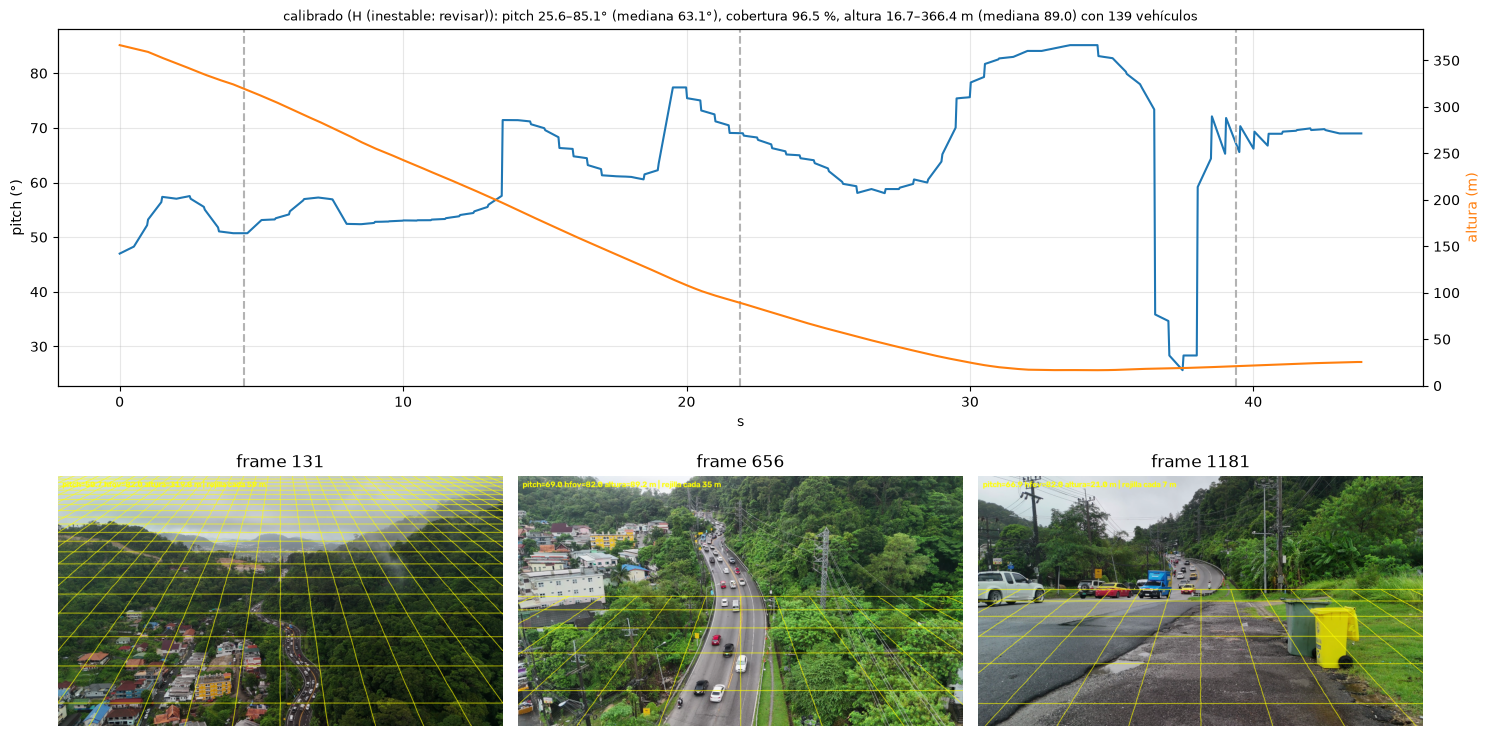

In [19]:
cam, info = calibrar_ucmc(VIDEO_PATH, detector, cfg, respaldo=UCMC_CAM_POR_VIDEO.get(VIDEO_PATH.stem),
                          cache_dir=f"comparativa_v13/{VIDEO_PATH.stem}")      # v13: pitch por frame + altura
display(pd.Series(info))
fig = ver_calibracion(VIDEO_PATH, cam, cfg, out=f"calibracion_{VIDEO_PATH.stem}.jpg")


### Paso B2 — Comparar todos los videos de la carpeta
Procesa cada video de `VIDEOS_DIR` (omite duplicados y los ya procesados con el mismo detector) y muestra la tabla completa y la de ganadores. Usa `DETECTORES`, `DETECTOR_POR_VIDEO`, `UCMC_CAM_POR_VIDEO` y `cfg` del Paso B.


In [20]:
VIDEOS_DIR = Path('/Users/Alex/Documents/videos_VIGIA')                       # <-- CAMBIAR por tu carpeta

resumen = comparar_carpeta(VIDEOS_DIR, DETECTORES, cfg, out_dir="comparativa_v13",  # todos los videos, sin duplicados
                           detector_por_video=DETECTOR_POR_VIDEO,               # v11: detector de cada video
                           ucmc_cam_por_video=UCMC_CAM_POR_VIDEO,               # v12: cámara de UCMC de cada video (v13: respaldo)
                           kinds=KINDS_V12)
display(resumen.set_index(["video", "variante"]))                                 # tabla completa
display(ganadores(resumen))                                                       # ganador por video y métrica


--- vigia_1.mp4 (detector obb) ---
calibrar_ucmc: calibrado (H): pitch 0.0–35.3° (mediana 24.9°), cobertura 77.4 %, altura 28.8–80.8 m (mediana 61.6) con 159 vehículos
UCMC manual | cámara: pitch 0.0°, hfov 82.0° | altura 96.7 m (estimada con 85 vehículos)
100 fotogramas
200 fotogramas
300 fotogramas
400 fotogramas
500 fotogramas
600 fotogramas
700 fotogramas
800 fotogramas
WARNING ⚠️ not enough matching points
FPS=24.00 | frames=897 | toma: movimiento suave (p90 = 0.73 px/frame) | salida: comparativa_v13/vigia_1
--- vigia_10.mp4 (detector coco) ---
calibrar_ucmc: calibrado (H): pitch 1.5–55.6° (mediana 23.4°), cobertura 100.0 %, altura 97.8–109.1 m (mediana 104.5) con 31 vehículos
UCMC manual | cámara: pitch 40°, hfov 82.0° | altura 102.9 m (estimada con 11 vehículos) | pitch estimado a ojo
100 fotogramas
200 fotogramas
300 fotogramas
400 fotogramas
500 fotogramas
600 fotogramas
700 fotogramas
800 fotogramas
900 fotogramas
1000 fotogramas
1100 fotogramas
1200 fotogramas
1300 fotograma

detector  ids_emitidos  tracks  vida_media_s  \
video    variante                                                 
vigia_1  propio_kf      obb           641     455          2.41   
         bytetrack      obb           695     422          2.09   
         botsort        obb           582     384          2.36   
         ucmc           obb           503     300          3.56   
vigia_10 propio_kf     coco           402     349          1.01   
         bytetrack     coco           550     319          0.79   
         botsort       coco           458     342          0.77   
         ucmc          coco           454     187          1.71   
vigia_11 propio_kf     coco           451     344          1.61   
         bytetrack     coco           456     277          1.58   
         botsort       coco           421     275          1.70   
         ucmc          coco           375     211          2.46   
vigia_2  propio_kf      obb           640     524          2.42   
         bytetrack      obb           889     404          2.48   
         botsort        obb           800     454          2.35   
         ucmc           obb           679     341          3.56   
vigia_3  propio_kf      obb           735     576          2.54   
         bytetrack      obb           902     462          2.87   
         botsort        obb           872     452          2.94   
         ucmc           obb           546     349          4.11   
vigia_4  propio_kf      obb            34      11          1.24   
         bytetrack      obb            34      21          0.39   
         botsort        obb            33      17          0.60   
         ucmc           obb            13      10          1.42   
vigia_5  propio_kf      obb            92      76          2.20   
         bytetrack      obb           102      63          2.27   
         botsort        obb            96      65          2.23   
         ucmc           obb            88      54          2.87   
vigia_6  propio_kf      obb            67      55          1.86   
         bytetrack      obb            71      48          1.70   
         botsort        obb            53      43          1.98   
         ucmc           obb            52      33          2.89   
vigia_8  propio_kf     coco           148     138          1.39   
         bytetrack     coco           191     129          1.01   
         botsort       coco           179     128          1.04   
         ucmc          coco           138      73          2.29   
vigia_9  propio_kf     coco           785     653          0.85   
         bytetrack     coco          1003     661          0.63   
         botsort       coco           878     641          0.67   
         ucmc          coco           789     399          1.29   

                    tracks_por_objeto  ids_por_minuto  duracion_mediana_s  \
video    variante                                                           
vigia_1  propio_kf               15.5           730.4                1.08   
         bytetrack               17.9           677.5                0.81   
         botsort                 15.9           616.5                1.04   
         ucmc                    10.5           481.6                2.31   
vigia_10 propio_kf               27.7           750.2                0.40   
         bytetrack               35.2           685.7                0.32   
         botsort                 36.1           735.2                0.27   
         ucmc                    16.3           402.0                0.78   
vigia_11 propio_kf               27.3           470.8                0.60   
         bytetrack               27.7           379.1                0.57   
         botsort                 25.8           376.3                0.67   
         ucmc                    17.9           288.8                0.93   
vigia_2  propio_kf                6.7          1942.8                1.08   
         bytetrack                6.5          14

,detector,tipo_toma,mov_camara_px_p90,objetos_prom,vida_media_s,tracks_por_objeto,ids_emitidos,cambios_estado_por_track
video,,,,,,,,
vigia_1,obb,movimiento suave,0.73,26.4,ucmc,ucmc,ucmc,bytetrack
vigia_10,coco,movimiento suave,1.31,10.7,ucmc,ucmc,propio_kf,bytetrack
vigia_11,coco,movimiento suave,2.49,11.3,ucmc,ucmc,ucmc,bytetrack
vigia_2,obb,movimiento suave,2.26,70.3,ucmc,ucmc,propio_kf,botsort
vigia_3,obb,estacionario,0.06,45.5,ucmc,ucmc,ucmc,bytetrack = botsort
vigia_4,obb,movimiento rapido,5.61,0.8,ucmc,ucmc,ucmc,bytetrack
vigia_5,obb,estacionario,0.03,4.4,ucmc,ucmc,ucmc,botsort
vigia_6,obb,estacionario,0.03,4.9,ucmc,ucmc,ucmc,bytetrack
vigia_8,coco,movimiento suave,1.01,9.9,ucmc,ucmc,ucmc,bytetrack


### Paso C — Cómo distinguir los trackers
0. **(v11) Mira la columna `detector`.** Compara trackers dentro de cada video; entre videos con detectores distintos, las cifras absolutas no son comparables.
1. **Primero, el tipo de toma.** Si es `estacionario`, la compensación de cámara no tiene nada que corregir: las diferencias vienen de cómo asocia cada tracker (p. ej. el Kalman de ByteTrack/BoT-SORT), no de la compensación. Para evaluar la compensación hacen falta videos con `movimiento suave` o `movimiento rapido` y con varios objetos (`objetos_prom`).
2. **Fragmentación normalizada:** `vida_media_s` (más alto, mejor) y `tracks_por_objeto` (más bajo, mejor). Son las métricas principales: no castigan al tracker que ve más objetos.
3. **Panel del mosaico:** `IDs (>=2 det.)` por tracker, contados igual en todos.
4. **Colores de ID:** si un mismo objeto cambia de color de recuadro, el tracker le cambió el ID.
5. **Cajas (v10):** `cajas_fusionadas_pct` y `cajas_grandes_sin_clase_pct` deberían ser bajos y parecidos en todos los trackers (dependen sobre todo del detector y de las propuestas, que son compartidos). Si uno es alto, mira el mosaico en ese video.
6. **Ablación (opcional, añadiendo variantes en `kinds`).** Compara por pares, solo cambia una cosa en cada uno:
   - `propio_kf` vs `propio_kf_sin_h` → efecto de la compensación con `H` (mismo código). Esperable: casi iguales en `estacionario`; ventaja de `propio_kf` en `movimiento rapido`.
   - `propio_kf` vs `propio` → efecto de Kalman.
   - `propio_kf` vs `botsort` → nuestra `H` frente al GMC de BoT-SORT.
   - `ucmc` vs `ucmc_sin_cmc` → (v12) ¿basta con absorber el movimiento de la cámara como ruido (UCMC "uniforme")? Esperable: casi iguales en `estacionario`; ventaja de `ucmc` en `movimiento rapido`.
   - `ucmc` vs `propio_kf` → (v12) **las dos reciben la misma `H`**: la diferencia es asociar en el suelo con MMD frente a asociar en la imagen con IoU.
8. **(v12) UCMC y la cámara.** Si UCMC va claramente peor en una toma oblicua, revisa primero su rejilla (Paso A2) y `ucmc_dets_fuera`: un pitch mal estimado proyecta mal todo el video. En tomas cenitales la proyección es casi solo un cambio de escala, así que ahí la comparación mide sobre todo **MMD frente a IoU**.
7. **Falsos movimientos:** `pct_frames_en_movimiento` y `cambios_estado_por_track` (parpadeo del estado).

**Límite:** las métricas no usan verdad de terreno. Para números concluyentes, anota a mano 2 o 3 clips cortos (p. ej. con CVAT en formato MOT) y mide HOTA/IDF1 con TrackEval, o usa un dataset de dron ya anotado (VisDrone-MOT, UAVDT).
9. **(v13) ¿Sirve la calibración automática?** Corre una vez con `kinds=KINDS_V12 + ("ucmc_manual",)` y compara `ucmc` (calibrada) con `ucmc_manual` (pitch a ojo del v12). Mira también `ucmc_dets_fuera` (debería bajar) y `ucmc_calib`: en las filas `respaldo` las dos usan la misma cámara.
